# Superstition-like behavioural concentration in RL — Extended Study

This notebook provides the complete experimental pipeline: the environment, Q-learning and Stable-Baselines3 algorithms (DQN, PPO, A2C), Tiers A–F experimental conditions, interval and hyperparameter checks, null simulations, bootstrap intervals, and familywise Holm–Bonferroni corrections.

**Run instructions**
1. Upload this notebook to Colab, or open it in Jupyter. Run the install cell once.
2. Review the configuration below **before** starting the experiments. The default configuration runs the full study: 8 Tier A/control seeds, 24 PPO seeds, 16 A2C null-test seeds, 15,000 steps, 1,000 circular shifts, and 10,000 bootstrap resamples.
3. Run cells in order. Each completed training run is saved under `results_v4/run_cache/`; repeating a cell reuses matching checkpoints. On Colab, set `OUTPUT_ROOT` to a persistent Drive directory if you need to resume after a runtime disconnection.
4. Download `superstitious_rl_v4_release.zip` at the end. It contains all generated figures, numeric tables, per-seed measurements, traces, metadata, and manuscript notes.

All runs generate aligned action/reward traces and configuration metadata. Shared configurations are automatically reused across experimental tiers, including Tier A/B/C/D overlaps.


In [1]:

%pip install -q stable-baselines3==2.9.0 gymnasium scipy pandas matplotlib


## 1. Configuration and reproducibility

The study runs on CPU using Stable-Baselines3 2.9.0 for reproducible execution. Package/platform versions and effective hyperparameters are recorded. Changing a training parameter produces a different checkpoint key. Complete action and reward traces also allow adjustments to analysis settings without retraining.

The final shift-analysis window is fixed at **3,000 steps**. The observed statistic is the modal fraction among the last **30 extrinsic reward events** in that window; every shifted mask uses exactly the same statistic and window. Entropy is computed as the mean of the last five logged 200-action-window entropies. These are distinct estimands and are labelled explicitly in exports.


In [2]:
from pathlib import Path
from collections import Counter, deque
from itertools import combinations
import gzip, hashlib, inspect, json, platform, shutil, sys
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import mannwhitneyu, kruskal, wilcoxon
import gymnasium as gym
from gymnasium import spaces
import torch
import stable_baselines3 as sb3
from stable_baselines3 import DQN, PPO, A2C
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.env_util import make_vec_env
from IPython.display import display

OUTPUT_ROOT = Path('results_v4')  # e.g. /content/drive/MyDrive/SuperstitiousRL/results_v4
CACHE_DIR = OUTPUT_ROOT / 'run_cache'
FIG_DIR = OUTPUT_ROOT / 'figures'
TABLE_DIR = OUTPUT_ROOT / 'tables'
for folder in (OUTPUT_ROOT, CACHE_DIR, FIG_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

N_SEEDS = 8
N_SEEDS_PPO_EXT = 24
N_SEEDS_A2C_NULL = 16
TOTAL_STEPS = 15000
N_ACTIONS = 4
INTERVAL = 10
EPISODE_LEN = 500
WINDOW = 200
LOG_EVERY = 300
FINAL_ENTROPY_POINTS = 5
RITUAL_TAIL = 30
FINAL_ANALYSIS_STEPS = 3000
N_SHIFTS = 1000
SHIFT_SEED = 271828
N_BOOT = 10000
BOOT_SEED = 12345
CI_LEVEL = 0.95
ALPHA = 0.05
N_NULL_SIMS = 2000
EQUIV_MARGIN = 0.5
RUN_TIER_D_SCHEDULES = True
RUN_TIER_E = True
RUN_A2C_45K_CONTROL = True
FORCE_RETRAIN = False  # True deliberately replaces matching completed checkpoints
DEVICE = 'cpu'
TRACE_SCHEMA = 'v4_full_actions_extrinsic_1'
ANALYSIS_VERSION = 'v4_tail30_window3000_shifts1000'

assert N_SEEDS == 8, 'The requested main comparison and learner controls use 8 seeds.'
assert N_SEEDS_PPO_EXT == 24 and N_SEEDS_A2C_NULL >= 16
assert N_SHIFTS == 1000
assert FINAL_ANALYSIS_STEPS >= WINDOW and TOTAL_STEPS >= FINAL_ANALYSIS_STEPS
if sb3.__version__ != '2.9.0':
    raise RuntimeError('Install SB3 2.9.0 and restart the kernel before continuing.')

ALGOS = ['Qlearning', 'DQN', 'PPO', 'A2C']
CONDITIONS = ['noncontingent', 'contingent']
SCHEDULES = ['fixed', 'variable', 'random']
TIER_B_ALGOS = ['Qlearning', 'PPO']
ENV_DEFAULTS = dict(n_actions=N_ACTIONS, interval=INTERVAL,
                    episode_len=EPISODE_LEN, reward_mode='noncontingent',
                    schedule_type='fixed', bonus=False, bonus_coef=0.5,
                    target_action=0)
QL_DEFAULTS = dict(alpha=0.1, gamma=0.9, epsilon_start=1.0,
                   epsilon_end=0.05, epsilon_decay_fraction=0.5)
DQN_OVERRIDES = dict(learning_starts=200, buffer_size=20000, train_freq=1,
                     target_update_interval=250, exploration_fraction=0.5,
                     exploration_final_eps=0.05)
MAIN_SB3_KWARGS = {'DQN': DQN_OVERRIDES,
                   'PPO': dict(n_steps=200, batch_size=100),
                   'A2C': dict(n_steps=5)}
RUN_REGISTRY = {}
np.random.seed(0)

def stable_seed(*parts):
    payload = json.dumps(parts, sort_keys=True, default=str).encode()
    return int(hashlib.sha256(payload).hexdigest()[:8], 16)

VERSIONS = dict(python=sys.version, platform=platform.platform(),
                stable_baselines3=sb3.__version__, gymnasium=gym.__version__,
                numpy=np.__version__, scipy=scipy.__version__,
                pandas=pd.__version__, torch=torch.__version__)
print(json.dumps(VERSIONS, indent=2))


{
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "stable_baselines3": "2.9.0",
  "gymnasium": "1.4.0",
  "numpy": "2.1.3",
  "scipy": "1.16.3",
  "pandas": "2.2.3",
  "torch": "2.11.0+cpu"
}


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 2. Environment, including zero and constant reward

The environment supports fixed, variable, and random noncontingent schedules, as well as a contingent target condition. Learner-level controls include `reward_mode='zero'` and `reward_mode='constant'` (extrinsic reward 1 on every step), with exploration bonuses disabled. All modes use the same observation, action space, truncation, and training budget. Schedule clocks and visit counts continue across episode truncations.

**Manuscript statement:** “To separate reward-driven fixation from learner dynamics, we include zero-reward and constant-reward controls.”


In [3]:
class SkinnerBoxEnv(gym.Env):
    metadata = {'render_modes': []}

    def __init__(self, n_actions=4, interval=10, episode_len=500,
                 reward_mode='noncontingent', schedule_type='fixed',
                 target_action=0, bonus=False, bonus_coef=0.5, seed=None):
        super().__init__()
        if reward_mode not in {'noncontingent', 'contingent', 'zero', 'constant'}:
            raise ValueError(reward_mode)
        if schedule_type not in {'fixed', 'variable', 'random'}:
            raise ValueError(schedule_type)
        self.n_actions, self.interval = n_actions, interval
        self.episode_len = episode_len
        self.reward_mode, self.schedule_type = reward_mode, schedule_type
        self.target_action, self.bonus = target_action, bonus
        self.bonus_coef = bonus_coef
        self.action_space = spaces.Discrete(n_actions)
        self.observation_space = spaces.Box(0.0, 1.0, shape=(1,), dtype=np.float32)
        self._schedule_rng = np.random.default_rng(seed)
        self._step_count = self._global_step = 0
        self._action_counts = np.zeros(n_actions)
        self._next_reward_step = self._draw_next_reward_step()

    def _draw_next_reward_step(self):
        if self.schedule_type == 'fixed':
            return self._global_step + self.interval
        if self.schedule_type == 'variable':
            low = max(1, int(self.interval * 0.5))
            high = int(self.interval * 1.5) + 1
            return self._global_step + int(self._schedule_rng.integers(low, high))
        return None

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self._step_count = 0
        return np.array([0.0], dtype=np.float32), {}

    def step(self, action):
        action = int(action)
        self._step_count += 1
        self._global_step += 1
        self._action_counts[action] += 1
        if self.reward_mode == 'zero':
            extrinsic = 0.0
        elif self.reward_mode == 'constant':
            extrinsic = 1.0
        elif self.reward_mode == 'contingent':
            extrinsic = float(action == self.target_action)
        elif self.schedule_type == 'random':
            extrinsic = float(self._schedule_rng.random() < 1.0 / self.interval)
        else:
            extrinsic = float(self._global_step >= self._next_reward_step)
            if extrinsic:
                self._next_reward_step = self._draw_next_reward_step()
        reward = extrinsic
        if self.bonus:
            reward += self.bonus_coef / np.sqrt(self._action_counts[action])
        info = {'extrinsic_reward': extrinsic, 'global_step': self._global_step}
        return (np.array([0.0], dtype=np.float32), float(reward), False,
                self._step_count >= self.episode_len, info)


def compute_entropy(actions, n_actions=N_ACTIONS):
    if len(actions) == 0:
        return float(np.log2(n_actions))
    counts = np.bincount(np.asarray(actions, dtype=int), minlength=n_actions)
    probs = counts[counts > 0] / counts.sum()
    return float(-np.sum(probs * np.log2(probs)))


def epsilon_greedy_entropy(epsilon=0.05, n_actions=N_ACTIONS):
    # Applies to a single fixed greedy action and exploration uniform over ALL actions.
    probs = np.full(n_actions, epsilon / n_actions)
    probs[0] += 1 - epsilon
    return float(-np.sum(probs * np.log2(probs)))


EPSILON_FLOOR = epsilon_greedy_entropy()
print(f'Population entropy with a fixed greedy action and epsilon=.05: {EPSILON_FLOOR:.4f} bits')
print('Finite 200-action empirical windows can be below this population value.')


Population entropy with a fixed greedy action and epsilon=.05: 0.2901 bits
Finite 200-action empirical windows can be below this population value.


## 3. Training, complete traces and resumable checkpoints

Tabular exploitation uses `np.argmax(Q)`: exact ties select the lowest-index action. With zero reward and zero initial Q-values, all values remain tied, so action 0 is chosen on exploitation steps. Exploration still samples uniformly from all four actions. This alone can concentrate behaviour. DQN's greedy action uses PyTorch `argmax`, also first-index on exact ties in this CPU implementation; PPO/A2C sample their categorical policy during training. The epsilon calculation above is a population benchmark for a stable greedy action, not a hard lower bound on a finite-window entropy estimate or on all possible policies.

A2C uses `n_steps=5` in the main study and learner controls; an `n_steps=200` configuration is evaluated as an under-updated control condition. Traces record the action **at the same step** as each extrinsic reward, ensuring temporal alignment. SB3 can overshoot a requested budget to complete a rollout; requested and actual step counts are both exported.


In [4]:
def record_step(storage, step, action, extrinsic):
    storage['actions'].append(int(action))
    storage['extrinsic_rewards'].append(float(extrinsic))
    storage['window'].append(int(action))
    if extrinsic > 0:
        storage['ritual_log'].append(int(action))
    if step % LOG_EVERY == 0:
        storage['entropy_log'].append([int(step), compute_entropy(storage['window'])])


def new_storage():
    return dict(actions=[], extrinsic_rewards=[], ritual_log=[], entropy_log=[],
                window=deque(maxlen=WINDOW))


def finish_storage(storage):
    storage['final_window'] = list(storage.pop('window'))
    storage['reward_timestamps'] = (np.flatnonzero(np.array(storage['extrinsic_rewards']) > 0) + 1).tolist()
    storage['actual_steps'] = len(storage['actions'])
    return storage


def train_qlearning(config):
    seed = config['seed']
    rng = np.random.default_rng(seed)
    env = SkinnerBoxEnv(**config['environment'], seed=seed)
    env.reset(seed=seed)
    q = np.zeros(N_ACTIONS)
    log = new_storage()
    kw = config['learner_kwargs']
    decay = max(1, int(config['total_steps'] * kw['epsilon_decay_fraction']))
    for step in range(1, config['total_steps'] + 1):
        epsilon = max(kw['epsilon_end'], kw['epsilon_start'] -
                      (kw['epsilon_start'] - kw['epsilon_end']) * step / decay)
        action = int(rng.integers(N_ACTIONS)) if rng.random() < epsilon else int(np.argmax(q))
        _, reward, terminated, truncated, info = env.step(action)
        q[action] += kw['alpha'] * (reward + kw['gamma'] * q.max() - q[action])
        record_step(log, step, action, info['extrinsic_reward'])
        if terminated or truncated:
            env.reset(seed=seed)
    env.close()
    log = finish_storage(log)
    log['Q'] = q.tolist()
    log['epsilon_final'] = epsilon
    return log


class TraceCallback(BaseCallback):
    def __init__(self):
        super().__init__()
        self.storage = new_storage()

    def _on_step(self):
        assert len(np.atleast_1d(self.locals['actions'])) == 1
        record_step(self.storage, self.num_timesteps,
                    np.atleast_1d(self.locals['actions'])[0],
                    self.locals['infos'][0]['extrinsic_reward'])
        return True


def train_sb3(config):
    env = make_vec_env(lambda: SkinnerBoxEnv(**config['environment'], seed=config['seed']),
                       n_envs=1, seed=config['seed'])
    callback = TraceCallback()
    model = {'DQN': DQN, 'PPO': PPO, 'A2C': A2C}[config['algorithm']](
        'MlpPolicy', env, seed=config['seed'], device=DEVICE, verbose=0,
        **config['learner_kwargs'])
    try:
        model.learn(total_timesteps=config['total_steps'], callback=callback)
        log = finish_storage(callback.storage)
        log['model_num_timesteps'] = int(model.num_timesteps)
        log['epsilon_final'] = float(model.exploration_rate) if config['algorithm'] == 'DQN' else None
        if config['algorithm'] in {'A2C', 'PPO'}:
            log['rollout_batches'] = int(model.num_timesteps // model.n_steps)
            log['optimizer_updates_reported'] = int(model._n_updates)
        return log
    finally:
        env.close()


def run_one(algorithm, seed, reward_mode='noncontingent', schedule_type='fixed',
            bonus=False, interval=INTERVAL, total_steps=TOTAL_STEPS,
            sb3_kwargs=None):
    environment = dict(ENV_DEFAULTS, reward_mode=reward_mode,
                       schedule_type=schedule_type, bonus=bonus, interval=interval)
    learner_kwargs = dict(QL_DEFAULTS if algorithm == 'Qlearning' else MAIN_SB3_KWARGS[algorithm])
    if sb3_kwargs:
        if algorithm == 'Qlearning':
            raise ValueError('Use QL_DEFAULTS for tabular overrides.')
        learner_kwargs.update(sb3_kwargs)
    config = dict(algorithm=algorithm, seed=int(seed), environment=environment,
                  learner_kwargs=learner_kwargs, total_steps=int(total_steps),
                  trace_schema=TRACE_SCHEMA, entropy_window=WINDOW,
                  entropy_log_every=LOG_EVERY, versions=VERSIONS, device=DEVICE)
    digest = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:20]
    key = f'{algorithm}_seed{seed}_{digest}'
    path = CACHE_DIR / f'{key}.json.gz'
    if path.exists() and not FORCE_RETRAIN:
        with gzip.open(path, 'rt', encoding='utf-8') as stream:
            result = json.load(stream)
        if result['config'] != config:
            raise RuntimeError(f'Checkpoint metadata mismatch: {path}')
        status = 'cached'
    else:
        print(f'RUN {key}: {reward_mode}/{schedule_type}, bonus={bonus}, I={interval}', flush=True)
        result = train_qlearning(config) if algorithm == 'Qlearning' else train_sb3(config)
        result.update(config=config, run_id=key)
        temp = path.with_name(path.name + '.partial')
        with gzip.open(temp, 'wt', encoding='utf-8') as stream:
            json.dump(result, stream, allow_nan=False)
        temp.replace(path)
        status = 'trained'
    assert len(result['actions']) == len(result['extrinsic_rewards']) == result['actual_steps']
    RUN_REGISTRY[key] = dict(run_id=key, cache_file=str(path), status=status,
                             algorithm=algorithm, seed=seed, actual_steps=result['actual_steps'],
                             requested_steps=total_steps, reward_mode=reward_mode,
                             schedule=schedule_type, bonus=bonus, interval=interval,
                             learner_kwargs=json.dumps(learner_kwargs, sort_keys=True))
    return result


def run_multiseed(algorithm, n_seeds=N_SEEDS, seeds=None, **kwargs):
    seed_list = list(range(n_seeds)) if seeds is None else list(seeds)
    return [run_one(algorithm, seed, **kwargs) for seed in seed_list]


# Source-based SB3 defaults: avoids constructing a reference model with a huge replay buffer.
params = inspect.signature(DQN.__init__).parameters
dqn_hparam_table = pd.DataFrame([
    {'parameter': k, 'SB3_default': str(params[k].default), 'override': v}
    for k, v in DQN_OVERRIDES.items()
])
display(dqn_hparam_table)


,parameter,SB3_default,override
0,learning_starts,100,200.00
1,buffer_size,1000000,20000.00
2,train_freq,4,1.00
3,target_update_interval,10000,250.00
4,exploration_fraction,0.1,0.50
5,exploration_final_eps,0.05,0.05


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 4. Metrics: raw concentration and excess over shifted timestamps

**Methodological rationale:** “Because reward timing is independent of action, ritual strength is expected to equal the modal-action frequency; we therefore report excess ritual strength relative to shifted reward timestamps.”

A finite-sample *maximum* modal fraction exhibits sampling bias. Raw ritual strength does not independently establish reward-dependent fixation. The circularly shifted baseline estimates the statistic's expected value conditional on the observed action trace and reward-event count.

For each run, the analysis retains the final 3,000 actions and the corresponding reward mask. Raw strength is computed over the last 30 reward events, and the **reward mask** is circularly shifted across 1,000 reproducibly sampled nonzero offsets. For each shift, the last 30 reward events are selected to recompute the modal fraction. Excess ritual strength is defined as the observed fraction minus the mean across these 1,000 shifted fractions. Action sequence order, reward count, and circular inter-event intervals are preserved. Periodic schedules can produce identical masks at different offsets; circular shifts estimate the conditional null expectation rather than independent replications.

The reported 95% bootstrap CI resamples **independent training seeds**, avoiding the conflation of shifted offsets with independent replications. Shift inference assumes approximate stationarity within the tail window and is descriptive. A CI containing zero does not establish equivalence to zero; endpoints should be reported directly without assuming absence of effect.

Zero-reward conditions have no extrinsic reward events (resulting in NaN). Constant reward has a degenerate shift baseline and exactly zero excess by construction. Contingent reward timing depends on action, so its shifted excess is not interpreted as noncontingent fixation; target-action rate serves as the primary learnability measure.


In [5]:
def ritual_metrics(action_log, tail=RITUAL_TAIL):
    if len(action_log) == 0:
        return {'ritual_strength': np.nan, 'ritual_streak': np.nan}
    recent = action_log[-tail:]
    strength = max(Counter(recent).values()) / len(recent)
    streak = longest = 1
    for a, b in zip(action_log[:-1], action_log[1:]):
        streak = streak + 1 if a == b else 1
        longest = max(longest, streak)
    return {'ritual_strength': float(strength), 'ritual_streak': int(longest)}


def modal_fraction(actions):
    return max(Counter(np.asarray(actions).tolist()).values()) / len(actions) if len(actions) else np.nan


def bootstrap_mean_ci(values, ci=CI_LEVEL, n_boot=N_BOOT, key='mean'):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < 2:
        return (float(values.mean()) if len(values) else np.nan, np.nan, np.nan)
    rng = np.random.default_rng(stable_seed(BOOT_SEED, key))
    means = np.array([rng.choice(values, len(values), replace=True).mean() for _ in range(n_boot)])
    lo, hi = np.quantile(means, [(1-ci)/2, 1-(1-ci)/2])
    return float(values.mean()), float(lo), float(hi)


_MEASUREMENT_CACHE = {}

def measure_run(run):
    analysis_key = (run['run_id'], FINAL_ANALYSIS_STEPS, RITUAL_TAIL, N_SHIFTS,
                    SHIFT_SEED, FINAL_ENTROPY_POINTS)
    if analysis_key in _MEASUREMENT_CACHE:
        return dict(_MEASUREMENT_CACHE[analysis_key])
    actions = np.asarray(run['actions'], dtype=int)
    rewards = np.asarray(run['extrinsic_rewards'], dtype=float)
    length = min(FINAL_ANALYSIS_STEPS, len(actions))
    tail_actions = actions[-length:]
    mask = rewards[-length:] > 0
    indexes = np.flatnonzero(mask)
    observed = modal_fraction(tail_actions[indexes[-RITUAL_TAIL:]] )
    legacy = ritual_metrics(run['ritual_log'])
    mode = run['config']['environment']['reward_mode']
    expected = excess = shift_sd = np.nan
    status = 'no_reward_events'
    if len(indexes) and mode != 'contingent':
        if np.all(mask):
            expected, excess, shift_sd = observed, 0.0, 0.0
            status = 'degenerate_all_steps'
        else:
            rng = np.random.default_rng(stable_seed(SHIFT_SEED, run['run_id']))
            offsets = rng.choice(np.arange(1, length), size=N_SHIFTS,
                                 replace=N_SHIFTS > length-1)
            shifted = np.empty(N_SHIFTS)
            for i, offset in enumerate(offsets):
                shifted_idx = np.sort((indexes + offset) % length)
                shifted[i] = modal_fraction(tail_actions[shifted_idx[-RITUAL_TAIL:]])
            expected, shift_sd = float(shifted.mean()), float(shifted.std(ddof=1))
            excess = float(observed - expected)
            status = 'noncontingent_shift_baseline'
    elif mode == 'contingent':
        status = 'contingent_timing_not_independent'
    entropy_values = [value for _, value in run['entropy_log'][-FINAL_ENTROPY_POINTS:]]
    if not entropy_values:
        raise ValueError('No entropy checkpoints; use TOTAL_STEPS >= LOG_EVERY.')
    row = dict(seed=run['config']['seed'], run_id=run['run_id'],
               final_entropy=float(np.mean(entropy_values)),
               ritual_strength=float(observed),
               legacy_ritual_strength=legacy['ritual_strength'],
               ritual_streak=legacy['ritual_streak'],
               shifted_strength_mean=expected, excess_ritual_strength=excess,
               shift_distribution_sd=shift_sd, shift_status=status,
               final_window_modal_action_frequency=float(modal_fraction(tail_actions)),
               analysis_window_steps=length, analysis_reward_count=len(indexes),
               ritual_events_used=min(RITUAL_TAIL, len(indexes)),
               target_rate=float(np.mean(actions[-WINDOW:] == 0)),
               actual_steps=run['actual_steps'])
    _MEASUREMENT_CACHE[analysis_key] = row
    return dict(row)


def final_entropy_vals(results):
    return np.array([measure_run(r)['final_entropy'] for r in results])


def target_rate_vals(results):
    return np.array([measure_run(r)['target_rate'] for r in results])


def summarize(results):
    measurements = [measure_run(r) for r in results]
    result = {}
    for metric in ['final_entropy', 'ritual_strength', 'ritual_streak',
                   'excess_ritual_strength', 'shifted_strength_mean']:
        vals = np.array([r[metric] for r in measurements], dtype=float)
        finite = vals[np.isfinite(vals)]
        result[metric+'_vals'] = vals
        result[metric+'_mean'] = float(finite.mean()) if len(finite) else np.nan
        # Preserve v3's ddof=0 descriptive SD convention; state it in the manuscript.
        result[metric+'_std'] = float(finite.std(ddof=0)) if len(finite) else np.nan
    return result


def group_table(results, names, table_name):
    rows = []
    for key, runs in results.items():
        key = key if isinstance(key, tuple) else (key,)
        row = dict(zip(names, key))
        row['n_seeds'] = len(runs)
        s = summarize(runs)
        for metric in ['final_entropy', 'ritual_strength', 'ritual_streak',
                       'excess_ritual_strength', 'shifted_strength_mean']:
            row[metric+'_mean'] = s[metric+'_mean']
            row[metric+'_sd_ddof0'] = s[metric+'_std']
        mean, lo, hi = bootstrap_mean_ci(s['excess_ritual_strength_vals'],
                                         key=(table_name, key, 'excess'))
        row.update(excess_ci95_lo=lo, excess_ci95_hi=hi,
                   n_excess_defined=int(np.isfinite(s['excess_ritual_strength_vals']).sum()))
        row['target_rate_mean_contingent_only'] = (float(target_rate_vals(runs).mean())
             if runs[0]['config']['environment']['reward_mode'] == 'contingent' else np.nan)
        rows.append(row)
    df = pd.DataFrame(rows)
    df.to_csv(TABLE_DIR / f'{table_name}.csv', index=False)
    return df


## 5. Statistical functions and correction families

Nonparametric tests (Mann–Whitney U, Kruskal–Wallis, Wilcoxon signed-rank), effect sizes, bootstrap confidence intervals, and familywise Holm–Bonferroni corrections are implemented below. Test families are grouped by hypothesis and metric (e.g., entropy comparisons, raw strength, streak length, learner controls, uniform-null baselines, and excess-versus-zero tests), as catalogued in the final traceability table.

Raw ritual strength represents descriptive action concentration; statistical significance on that metric alone does not imply reward-timing dependency. Excess ritual strength relative to shifted timestamps provides the specific measure of reward-event alignment.


In [6]:
# ---- Bootstrap CIs, Holm-Bonferroni correction and epsilon-squared (v3: idempotent logging,
# `context` field, and m / Holm rank / multiplier columns so the corrected-p table is traceable) ----

_boot_rng = np.random.default_rng(BOOT_SEED)


TEST_LOG = []


def _test_key(r):
    return (r["tier"], r["family"], r.get("context", ""), r["comparison"], r["metric"])


def _log_test(rec):
    """Idempotent: re-running a stats cell REPLACES its earlier records instead of appending duplicates
    (duplicates would silently inflate m and every corrected p-value)."""
    key = _test_key(rec)
    TEST_LOG[:] = [r for r in TEST_LOG if _test_key(r) != key]
    TEST_LOG.append(rec)


def bootstrap_diff_ci(a, b, n_boot=N_BOOT, ci=CI_LEVEL, rng=None):
    """Bootstrap CI for the difference in means (a - b), resampling within each group."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    rng = np.random.default_rng(BOOT_SEED) if rng is None else rng
    na, nb = len(a), len(b)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        sa = a[rng.integers(0, na, na)]
        sb = b[rng.integers(0, nb, nb)]
        diffs[i] = sa.mean() - sb.mean()
    lo = np.percentile(diffs, (1 - ci) / 2 * 100)
    hi = np.percentile(diffs, (1 + ci) / 2 * 100)
    return float(a.mean() - b.mean()), float(lo), float(hi)


def epsilon_squared_kw(H, n, k):
    """Epsilon-squared effect size for Kruskal-Wallis (Tomczak & Tomczak, 2014):
    eps^2 = (H - k + 1) / (n - k). Roughly: 0.01 small, 0.08 medium, 0.26 large."""
    if n - k <= 0:
        return float("nan")
    return float((H - k + 1) / (n - k))


def holm_bonferroni(pvals, alpha=ALPHA):
    """Holm-Bonferroni step-down correction. Returns (corrected_pvals, reject_mask),
    both in the original input order. Ties are broken stably so ranks are reproducible."""
    pvals = np.asarray(pvals, dtype=float)
    m = len(pvals)
    order = np.argsort(pvals, kind="stable")
    corrected_sorted = np.empty(m)
    running_max = 0.0
    for i, idx in enumerate(order):
        adj = (m - i) * pvals[idx]
        running_max = max(running_max, adj)
        corrected_sorted[i] = min(running_max, 1.0)
    corrected = np.empty(m)
    corrected[order] = corrected_sorted
    reject = corrected < alpha
    return corrected, reject


def _design(fam):
    if fam in ("final_entropy", "ritual_strength", "ritual_streak"):
        return "original_design_reanalysis"
    if fam.startswith("interval_sensitivity"):
        return "post_hoc_robustness"
    return "reviewer_requested" if fam.startswith("revision_") else "supplementary"


def apply_family_correction(test_log=None, alpha=ALPHA):
    """Groups the test log by 'family' and applies Holm-Bonferroni within each family.
    Returns a DataFrame with raw and corrected p-values PLUS family size m, Holm rank (1 = smallest raw p)
    and the Holm multiplier (m - rank + 1), so every corrected p can be recomputed by hand."""
    test_log = TEST_LOG if test_log is None else test_log
    df = pd.DataFrame(test_log)
    if "context" not in df.columns:
        df["context"] = ""
    df["context"] = df["context"].fillna("")
    df["p_corrected"] = np.nan
    df["significant_corrected"] = False
    df["m"] = 0
    df["holm_rank"] = 0
    df["multiplier"] = 0
    for fam, idx in df.groupby("family").groups.items():
        idx = list(idx)
        pvals = df.loc[idx, "p_raw"].values
        corrected, reject = holm_bonferroni(pvals, alpha=alpha)
        order = np.argsort(pvals, kind="stable")
        ranks = np.empty(len(idx), dtype=int)
        ranks[order] = np.arange(1, len(idx) + 1)
        df.loc[idx, "p_corrected"] = corrected
        df.loc[idx, "significant_corrected"] = reject
        df.loc[idx, "m"] = len(idx)
        df.loc[idx, "holm_rank"] = ranks
        df.loc[idx, "multiplier"] = len(idx) - ranks + 1
    df["significant_raw"] = df["p_raw"] < alpha
    df["design"] = df["family"].map(_design)
    for c in ("m", "holm_rank", "multiplier"):
        df[c] = df[c].astype(int)
    return df


def cohens_d(a, b):
    a, b = np.array(a), np.array(b)
    pooled_std = np.sqrt(((len(a) - 1) * a.std(ddof=1) ** 2 +
                           (len(b) - 1) * b.std(ddof=1) ** 2) / (len(a) + len(b) - 2))
    return float((a.mean() - b.mean()) / pooled_std) if pooled_std > 0 else 0.0


def compare_two(vals_a, vals_b, label_a, label_b, metric_name="", family=None, tier="", context="", log=True):
    """Mann-Whitney U + Cohen's d + bootstrap 95% CI on the mean difference; recorded to TEST_LOG (unless
    log=False, used for descriptive sensitivity prints). p printed here is UNCORRECTED -- see Section 7."""
    stat, p = mannwhitneyu(vals_a, vals_b, alternative="two-sided")
    d = cohens_d(vals_a, vals_b)
    diff, lo, hi = bootstrap_diff_ci(vals_a, vals_b)
    fam = family or metric_name
    if log:
        _log_test({
            "tier": tier, "context": context, "test": "mannwhitney", "family": fam,
            "comparison": f"{label_a} vs {label_b}", "metric": metric_name,
            "p_raw": p, "stat": stat, "cohens_d": d,
            "diff": diff, "ci_lo": lo, "ci_hi": hi,
            "n_a": len(vals_a), "n_b": len(vals_b),
        })
    print(f"  {metric_name} | {context} {label_a} vs {label_b}: "
          f"Mann-Whitney p={p:.4f} (uncorrected), Cohen's d={d:.2f}, "
          f"diff={diff:.3f} [95% CI {lo:.3f}, {hi:.3f}]" + ("" if log else "  [not logged]"))
    return p, d


def compare_many(vals_list, labels, metric_name="", family=None, tier="", context="", log=True):
    """Kruskal-Wallis + epsilon-squared; recorded to TEST_LOG (unless log=False). p is UNCORRECTED."""
    stat, p = (0.0, 1.0) if np.unique(np.concatenate(vals_list)).size == 1 else kruskal(*vals_list)
    n_total = sum(len(v) for v in vals_list)
    k = len(vals_list)
    eps2 = epsilon_squared_kw(stat, n_total, k)
    fam = family or metric_name
    if log:
        _log_test({
            "tier": tier, "context": context, "test": "kruskal", "family": fam,
            "comparison": " vs ".join(str(l) for l in labels), "metric": metric_name,
            "p_raw": p, "stat": stat, "epsilon_sq": eps2,
            "n_total": n_total, "k": k,
        })
    print(f"  {metric_name} | {context} Kruskal-Wallis across {labels}: "
          f"p={p:.4f} (uncorrected), epsilon^2={eps2:.3f}" + ("" if log else "  [not logged]"))
    return p, eps2


## 6. Tier A — Main comparison across algorithms

All four algorithms evaluate seeds 0–7 for the primary Tier A comparisons. Main A2C uses `n_steps=5`. The A2C noncontingent sample is additionally evaluated across 16 seeds for the uniform-null baseline analysis, maintaining a balanced design across algorithms for the primary Tier A tests.


In [9]:
results_A = {}
for algo in ALGOS:
    for condition in CONDITIONS:
        results_A[(algo, condition)] = run_multiseed(algo, reward_mode=condition)

results_A2C_null = list(results_A[('A2C', 'noncontingent')]) + run_multiseed(
    'A2C', seeds=range(N_SEEDS, N_SEEDS_A2C_NULL), reward_mode='noncontingent')
df_A = group_table(results_A, ['algorithm', 'condition'], 'Table3_TierA')
display(df_A)

for algo in ALGOS:
    nc, ct = summarize(results_A[(algo, 'noncontingent')]), summarize(results_A[(algo, 'contingent')])
    compare_two(nc['final_entropy_vals'], ct['final_entropy_vals'],
                'noncontingent', 'contingent', 'final_entropy', tier='A', context=algo)
for metric in ['final_entropy', 'ritual_streak']:
    compare_many([summarize(results_A[(a, 'noncontingent')])[metric+'_vals'] for a in ALGOS],
                 ALGOS, metric, tier='A', context='noncontingent_n8_corrected_A2C')


RUN PPO_seed5_3e21a16e58d5c323882c: contingent/fixed, bonus=False, I=10
RUN PPO_seed6_e87c26a96e53da7ed690: contingent/fixed, bonus=False, I=10
RUN PPO_seed7_cb7b6e3a0cadbc46037c: contingent/fixed, bonus=False, I=10
RUN A2C_seed0_80f9909a895f905ca67b: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed1_f47066f16080a82a25fa: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed2_b994879f928a10c9d57c: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed3_789d16bfa32a713e5027: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed4_80e490d3fe9be346e64a: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed5_cd84555a4b87d34f4aa5: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed6_b5c9bfe95f5f22884544: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed7_bc9f8cfc60a8b3f764c2: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed0_0e016b1c213853f6c221: contingent/fixed, bonus=False, I=10
RUN A2C_seed1_c3ff4884e92d37b747b0: contingent/fixed, bonus=False, I=10
RUN A2C_seed2_7be2b8e2c9e9295e5f83: cont

,algorithm,condition,n_seeds,final_entropy_mean,final_entropy_sd_ddof0,ritual_strength_mean,ritual_strength_sd_ddof0,ritual_streak_mean,ritual_streak_sd_ddof0,excess_ritual_strength_mean,excess_ritual_strength_sd_ddof0,shifted_strength_mean_mean,shifted_strength_mean_sd_ddof0,excess_ci95_lo,excess_ci95_hi,n_excess_defined,target_rate_mean_contingent_only
0,Qlearning,noncontingent,8,0.506590,0.123992,0.829167,0.163671,90.250,22.415118,0.030267,0.019906,0.798900,0.158861,0.016592,0.044100,8,NaN
1,Qlearning,contingent,8,0.263627,0.036412,1.000000,0.000000,11764.125,29.771788,NaN,NaN,NaN,NaN,NaN,NaN,0,0.966875
2,DQN,noncontingent,8,1.709226,0.133931,0.425000,0.087797,14.250,2.586020,0.011271,0.021439,0.413729,0.084386,-0.003167,0.026746,8,NaN
3,DQN,contingent,8,0.263091,0.019892,1.000000,0.000000,11778.250,54.200438,NaN,NaN,NaN,NaN,NaN,NaN,0,0.961875
4,PPO,noncontingent,8,1.682194,0.555209,0.495833,0.182146,12.750,13.016816,0.011700,0.070473,0.484133,0.209501,-0.039388,0.060017,8,NaN
5,PPO,contingent,8,0.036200,0.022135,1.000000,0.000000,13106.750,44.882485,NaN,NaN,NaN,NaN,NaN,NaN,0,0.998750
6,A2C,noncontingent,8,1.763882,0.451394,0.466667,0.139443,14.000,12.469964,0.025496,0.051584,0.441171,0.154654,-0.010221,0.060630,8,NaN
7,A2C,contingent,8,0.001135,0.003004,1.000000,0.000000,14788.125,40.615383,NaN,NaN,NaN,NaN,NaN,NaN,0,1.000000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  final_entropy | Qlearning noncontingent vs contingent: Mann-Whitney p=0.0002 (uncorrected), Cohen's d=2.49, diff=0.243 [95% CI 0.157, 0.333]
  final_entropy | DQN noncontingent vs contingent: Mann-Whitney p=0.0002 (uncorrected), Cohen's d=14.13, diff=1.446 [95% CI 1.349, 1.532]
  final_entropy | PPO noncontingent vs contingent: Mann-Whitney p=0.0009 (uncorrected), Cohen's d=3.92, diff=1.646 [95% CI 1.226, 1.934]
  final_entropy | A2C noncontingent vs contingent: Mann-Whitney p=0.0006 (uncorrected), Cohen's d=5.17, diff=1.763 [95% CI 1.414, 1.961]
  final_entropy | noncontingent_n8_corrected_A2C Kruskal-Wallis across ['Qlearning', 'DQN', 'PPO', 'A2C']: p=0.0009 (uncorrected), epsilon^2=0.485
  ritual_streak | noncontingent_n8_corrected_A2C Kruskal-Wallis across ['Qlearning', 'DQN', 'PPO', 'A2C']: p=0.0001 (uncorrected), epsilon^2=0.642


## 7. Learner-level controls — zero reward and reward every step

Four algorithms × two controls × eight seeds = **64 runs**. Main A2C uses five-step rollouts. These controls use identical learning and exploration settings to the main conditions. Only entropy and action concentration are interpreted for the zero-reward control. Constant-reward excess is identically zero by construction and cannot validate reward-locking.

Fixed noncontingent reward is compared against each learner's two controls. There are eight entropy comparisons in the `revision_learner_controls_entropy` Holm family. These are two-sided comparisons; interpret effect direction and confidence intervals alongside statistical significance.


In [10]:
results_controls = {}
for algo in ALGOS:
    for mode in ['zero', 'constant']:
        results_controls[(algo, mode)] = run_multiseed(algo, reward_mode=mode, bonus=False)
df_controls = group_table(results_controls, ['algorithm', 'condition'], 'Learner_controls')
display(df_controls)
for algo in ALGOS:
    nc = summarize(results_A[(algo, 'noncontingent')])
    for mode in ['zero', 'constant']:
        control = summarize(results_controls[(algo, mode)])
        compare_two(nc['final_entropy_vals'], control['final_entropy_vals'],
                    'fixed_noncontingent', mode, 'final_entropy',
                    family='revision_learner_controls_entropy', tier='Controls', context=algo)


RUN DQN_seed0_35a528afb509cb4edca8: zero/fixed, bonus=False, I=10
RUN DQN_seed1_90d82cb4fce8f90cd4e4: zero/fixed, bonus=False, I=10
RUN DQN_seed2_86d97b0634ceeb676953: zero/fixed, bonus=False, I=10
RUN DQN_seed3_d664cdfbe4aeec8dbe03: zero/fixed, bonus=False, I=10
RUN DQN_seed4_ee9a5f61f81af86ba18b: zero/fixed, bonus=False, I=10
RUN DQN_seed5_711ba60f69da827f85cd: zero/fixed, bonus=False, I=10
RUN DQN_seed6_d4a04df656885c4441e4: zero/fixed, bonus=False, I=10
RUN DQN_seed7_52364823723833087e17: zero/fixed, bonus=False, I=10
RUN DQN_seed0_993a086775ef3e823aa6: constant/fixed, bonus=False, I=10
RUN DQN_seed1_d245157aab7eb29d4392: constant/fixed, bonus=False, I=10
RUN DQN_seed2_9f177430b31deb2f824a: constant/fixed, bonus=False, I=10
RUN DQN_seed3_d81aad234af05c14af27: constant/fixed, bonus=False, I=10
RUN DQN_seed4_110a0769db880d352a19: constant/fixed, bonus=False, I=10
RUN DQN_seed5_1184caae6634eeaecf41: constant/fixed, bonus=False, I=10
RUN DQN_seed6_c4d136d29baad8fab4d0: constant/fixed, 

,algorithm,condition,n_seeds,final_entropy_mean,final_entropy_sd_ddof0,ritual_strength_mean,ritual_strength_sd_ddof0,ritual_streak_mean,ritual_streak_sd_ddof0,excess_ritual_strength_mean,excess_ritual_strength_sd_ddof0,shifted_strength_mean_mean,shifted_strength_mean_sd_ddof0,excess_ci95_lo,excess_ci95_hi,n_excess_defined,target_rate_mean_contingent_only
0,Qlearning,zero,8,0.263627,0.036412,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
1,Qlearning,constant,8,0.263627,0.036412,0.970833,0.019983,163.500,34.365681,0.0,0.0,0.970833,0.019983,0.0,0.0,8,NaN
2,DQN,zero,8,1.977309,0.012567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
3,DQN,constant,8,1.845624,0.042765,0.950000,0.062361,61.500,8.803408,0.0,0.0,0.950000,0.062361,0.0,0.0,8,NaN
4,PPO,zero,8,1.988989,0.003148,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
5,PPO,constant,8,1.988517,0.003877,0.341667,0.043301,7.375,0.695971,0.0,0.0,0.341667,0.043301,0.0,0.0,8,NaN
6,A2C,zero,8,1.988989,0.003148,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
7,A2C,constant,8,1.777445,0.532772,0.412500,0.192164,18.000,26.466961,0.0,0.0,0.412500,0.192164,0.0,0.0,8,NaN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  final_entropy | Qlearning fixed_noncontingent vs zero: Mann-Whitney p=0.0002 (uncorrected), Cohen's d=2.49, diff=0.243 [95% CI 0.157, 0.333]
  final_entropy | Qlearning fixed_noncontingent vs constant: Mann-Whitney p=0.0002 (uncorrected), Cohen's d=2.49, diff=0.243 [95% CI 0.157, 0.333]
  final_entropy | DQN fixed_noncontingent vs zero: Mann-Whitney p=0.0002 (uncorrected), Cohen's d=-2.64, diff=-0.268 [95% CI -0.365, -0.182]
  final_entropy | DQN fixed_noncontingent vs constant: Mann-Whitney p=0.0499 (uncorrected), Cohen's d=-1.28, diff=-0.136 [95% CI -0.236, -0.045]
  final_entropy | PPO fixed_noncontingent vs zero: Mann-Whitney p=0.0002 (uncorrected), Cohen's d=-0.73, diff=-0.307 [95% CI -0.724, -0.022]
  final_entropy | PPO fixed_noncontingent vs constant: Mann-Whitney p=0.0002 (uncorrected), Cohen's d=-0.73, diff=-0.306 [95% CI -0.723, -0.021]
  final_entropy | A2C fixed_noncontingent vs zero: Mann-Whitney p=0.0006 (uncorrected), Cohen's d=-0.66, diff=-0.225 [95% CI -0.574, -0.02

## 8. Tiers B and C — schedules and count-based bonus

Q-learning evaluates eight seeds per condition; PPO evaluates 24 seeds per condition to provide enhanced statistical power for detecting subtle schedule differences. Shared fixed/no-bonus configurations reuse the Tier A runs. Exploration bonus conditions evaluate the count-based bonus across schedules. Terminology in tables and legends uses **bonus**.


In [11]:
results_B = {}
for algo in TIER_B_ALGOS:
    for schedule in SCHEDULES:
        n = N_SEEDS_PPO_EXT if algo == 'PPO' else N_SEEDS
        if schedule == 'fixed':
            runs = list(results_A[(algo, 'noncontingent')])
            runs += run_multiseed(algo, seeds=range(N_SEEDS, n))
        else:
            runs = run_multiseed(algo, n_seeds=n, schedule_type=schedule)
        results_B[(algo, schedule)] = runs
df_B = group_table(results_B, ['algorithm', 'schedule'], 'Table6_TierB')
display(df_B)
for algo in TIER_B_ALGOS:
    for metric in ['final_entropy', 'ritual_strength']:
        compare_many([summarize(results_B[(algo, s)])[metric+'_vals'] for s in SCHEDULES],
                     SCHEDULES, metric, tier='B', context=algo)
    for s1, s2 in combinations(SCHEDULES, 2):
        compare_two(final_entropy_vals(results_B[(algo, s1)]), final_entropy_vals(results_B[(algo, s2)]),
                    s1, s2, 'final_entropy', family='supp_tierB_pairwise_entropy',
                    tier='B-post', context=algo)

results_C = {}
for algo in TIER_B_ALGOS:
    n = N_SEEDS_PPO_EXT if algo == 'PPO' else N_SEEDS
    results_C[(algo, False)] = results_B[(algo, 'fixed')]
    results_C[(algo, True)] = run_multiseed(algo, n_seeds=n, bonus=True)
df_C = group_table(results_C, ['algorithm', 'bonus'], 'Table10_TierC')
display(df_C)
for algo in TIER_B_ALGOS:
    for metric in ['final_entropy', 'ritual_strength']:
        compare_two(summarize(results_C[(algo, False)])[metric+'_vals'],
                    summarize(results_C[(algo, True)])[metric+'_vals'],
                    'bonus OFF', 'bonus ON', metric, tier='C', context=algo)


RUN Qlearning_seed0_78475ac0805f07be5b92: noncontingent/variable, bonus=False, I=10
RUN Qlearning_seed1_d5e38ed00f4dc7665978: noncontingent/variable, bonus=False, I=10
RUN Qlearning_seed2_5593a19876925ab69ab8: noncontingent/variable, bonus=False, I=10
RUN Qlearning_seed3_d37b60cf4ed728da4240: noncontingent/variable, bonus=False, I=10
RUN Qlearning_seed4_3e58693215c6b8997382: noncontingent/variable, bonus=False, I=10
RUN Qlearning_seed5_abaadadb69e97a194bb2: noncontingent/variable, bonus=False, I=10
RUN Qlearning_seed6_99cdce3e18e13a473a96: noncontingent/variable, bonus=False, I=10
RUN Qlearning_seed7_5a669ab9ec5d01b7b6af: noncontingent/variable, bonus=False, I=10
RUN Qlearning_seed0_e35beed171e1b30b46c4: noncontingent/random, bonus=False, I=10
RUN Qlearning_seed1_6b85e3eba435076debac: noncontingent/random, bonus=False, I=10
RUN Qlearning_seed2_9cf87006ee3fff4f2046: noncontingent/random, bonus=False, I=10
RUN Qlearning_seed3_01e8a677627e1595b199: noncontingent/random, bonus=False, I=10


,algorithm,schedule,n_seeds,final_entropy_mean,final_entropy_sd_ddof0,ritual_strength_mean,ritual_strength_sd_ddof0,ritual_streak_mean,ritual_streak_sd_ddof0,excess_ritual_strength_mean,excess_ritual_strength_sd_ddof0,shifted_strength_mean_mean,shifted_strength_mean_sd_ddof0,excess_ci95_lo,excess_ci95_hi,n_excess_defined,target_rate_mean_contingent_only
0,Qlearning,fixed,8,0.506590,0.123992,0.829167,0.163671,90.250000,22.415118,0.030267,0.019906,0.798900,0.158861,0.016462,0.044037,8,NaN
1,Qlearning,variable,8,0.933351,0.120028,0.733333,0.181046,68.750000,16.983448,0.021371,0.026383,0.711963,0.169137,0.003675,0.040346,8,NaN
2,Qlearning,random,8,1.027609,0.193395,0.612500,0.202716,55.500000,15.905974,0.032192,0.094734,0.580308,0.166986,-0.034871,0.094446,8,NaN
3,PPO,fixed,24,1.624629,0.584096,0.502778,0.221927,19.250000,34.261555,-0.001233,0.057545,0.504011,0.223740,-0.023850,0.021994,24,NaN
4,PPO,variable,24,1.618025,0.538231,0.486111,0.219831,13.458333,17.240889,-0.015896,0.033979,0.502007,0.207905,-0.030179,-0.002750,24,NaN
5,PPO,random,24,1.771547,0.331038,0.461111,0.153860,8.708333,4.747624,0.012986,0.075522,0.448125,0.143706,-0.015701,0.044246,24,NaN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  final_entropy | Qlearning Kruskal-Wallis across ['fixed', 'variable', 'random']: p=0.0004 (uncorrected), epsilon^2=0.655
  ritual_strength | Qlearning Kruskal-Wallis across ['fixed', 'variable', 'random']: p=0.0995 (uncorrected), epsilon^2=0.125
  final_entropy | Qlearning fixed vs variable: Mann-Whitney p=0.0002 (uncorrected), Cohen's d=-3.27, diff=-0.427 [95% CI -0.547, -0.309]
  final_entropy | Qlearning fixed vs random: Mann-Whitney p=0.0002 (uncorrected), Cohen's d=-3.00, diff=-0.521 [95% CI -0.679, -0.364]
  final_entropy | Qlearning variable vs random: Mann-Whitney p=0.3823 (uncorrected), Cohen's d=-0.55, diff=-0.094 [95% CI -0.249, 0.064]
  final_entropy | PPO Kruskal-Wallis across ['fixed', 'variable', 'random']: p=0.8878 (uncorrected), epsilon^2=-0.026
  ritual_strength | PPO Kruskal-Wallis across ['fixed', 'variable', 'random']: p=0.7594 (uncorrected), epsilon^2=-0.021
  final_entropy | PPO fixed vs variable: Mann-Whitney p=0.6876 (uncorrected), Cohen's d=0.01, diff=0.007 

,algorithm,bonus,n_seeds,final_entropy_mean,final_entropy_sd_ddof0,ritual_strength_mean,ritual_strength_sd_ddof0,ritual_streak_mean,ritual_streak_sd_ddof0,excess_ritual_strength_mean,excess_ritual_strength_sd_ddof0,shifted_strength_mean_mean,shifted_strength_mean_sd_ddof0,excess_ci95_lo,excess_ci95_hi,n_excess_defined,target_rate_mean_contingent_only
0,Qlearning,False,8,0.506590,0.123992,0.829167,0.163671,90.250000,22.415118,0.030267,0.019906,0.798900,0.158861,0.016666,0.044242,8,NaN
1,Qlearning,True,8,0.627550,0.095312,0.841667,0.148838,80.250000,19.142557,0.031100,0.019490,0.810567,0.141130,0.017204,0.044704,8,NaN
2,PPO,False,24,1.624629,0.584096,0.502778,0.221927,19.250000,34.261555,-0.001233,0.057545,0.504011,0.223740,-0.024457,0.021763,24,NaN
3,PPO,True,24,1.649595,0.495833,0.501389,0.191117,17.291667,33.452054,-0.001932,0.075296,0.503321,0.196953,-0.031922,0.028879,24,NaN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  final_entropy | Qlearning bonus OFF vs bonus ON: Mann-Whitney p=0.0499 (uncorrected), Cohen's d=-1.02, diff=-0.121 [95% CI -0.226, -0.012]
  ritual_strength | Qlearning bonus OFF vs bonus ON: Mann-Whitney p=1.0000 (uncorrected), Cohen's d=-0.07, diff=-0.013 [95% CI -0.162, 0.142]
  final_entropy | PPO bonus OFF vs bonus ON: Mann-Whitney p=0.7966 (uncorrected), Cohen's d=-0.05, diff=-0.025 [95% CI -0.334, 0.278]
  ritual_strength | PPO bonus OFF vs bonus ON: Mann-Whitney p=0.6552 (uncorrected), Cohen's d=0.01, diff=0.001 [95% CI -0.114, 0.118]


## 9. Uniform-policy nulls and per-seed PPO counts

The uniform-policy null serves as a baseline comparator for **concentration relative to uniform sampling**, not as an explanation of learner dynamics or a reward-timing test. It uses the same final-entropy estimator (five 200-action windows) and a modal fraction of 30 reward-event actions. Tests are two-sided Wilcoxon signed-rank tests against the simulated null mean, Holm-corrected across the four algorithms within each metric family.

Q-learning and DQN evaluate eight seeds, PPO evaluates all **24** fixed/no-bonus seeds, and main A2C evaluates **16** noncontingent seeds. Reporting includes seed counts below the null entropy 5th percentile and above the raw-strength 95th percentile. These counts describe sample concentration; neither count serves as a test of excess ritual strength or an individual-seed significance test.


In [12]:
def null_baseline(n_sims=N_NULL_SIMS, seed=777):
    rng = np.random.default_rng(seed)
    entropy, strength, streak = [], [], []
    for _ in range(n_sims):
        entropy.append(np.mean([compute_entropy(rng.integers(N_ACTIONS, size=WINDOW))
                                for _ in range(FINAL_ENTROPY_POINTS)]))
        rm = ritual_metrics(rng.integers(N_ACTIONS, size=TOTAL_STEPS // INTERVAL).tolist())
        strength.append(rm['ritual_strength'])
        streak.append(rm['ritual_streak'])
    return dict(entropy_mean=float(np.mean(entropy)), entropy_p05=float(np.percentile(entropy, 5)),
                strength_mean=float(np.mean(strength)), strength_p95=float(np.percentile(strength, 95)),
                streak_mean=float(np.mean(streak)), streak_p95=float(np.percentile(streak, 95)))


def compare_one_sample(values, mu0, metric, family, tier, context):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < 2:
        raise ValueError(f'Need >=2 finite independent seeds for {context}/{metric}')
    diffs = values - mu0
    stat, p = (0.0, 1.0) if np.all(diffs == 0) else wilcoxon(diffs, alternative='two-sided')
    _log_test(dict(tier=tier, context=context, test='wilcoxon_1sample', family=family,
                   comparison=f'{context} vs null({mu0:.6f})', metric=metric,
                   p_raw=float(p), stat=float(stat), n=len(values), mu0=mu0,
                   diff=float(diffs.mean())))
    print(f'{context}: {metric}, n={len(values)}, raw p={p:.6g}')


NULL = null_baseline()
NULL_RUNS = {a: results_A[(a, 'noncontingent')] for a in ALGOS}
NULL_RUNS['PPO'] = results_B[('PPO', 'fixed')]
NULL_RUNS['A2C'] = results_A2C_null
df_null = group_table(NULL_RUNS, ['algorithm'], 'Table5_Null_comparison')
null_count_rows = []
for algo, runs in NULL_RUNS.items():
    s = summarize(runs)
    for metric, ref in [('final_entropy', 'entropy_mean'), ('ritual_strength', 'strength_mean')]:
        compare_one_sample(s[metric+'_vals'], NULL[ref], metric,
                           'revision_uniform_null_'+metric, 'Null', algo)
    compare_one_sample(s['excess_ritual_strength_vals'], 0.0, 'excess_ritual_strength',
                       'revision_excess_vs_zero', 'Shift', algo)
    null_count_rows.append(dict(algorithm=algo, n_seeds=len(runs),
        n_entropy_below_uniform_p05=int((s['final_entropy_vals'] < NULL['entropy_p05']).sum()),
        n_raw_strength_above_uniform_p95=int((s['ritual_strength_vals'] > NULL['strength_p95']).sum()),
        raw_strength_threshold=NULL['strength_p95'], entropy_threshold=NULL['entropy_p05']))
df_seed_counts = pd.DataFrame(null_count_rows)
df_null = df_null.merge(df_seed_counts, on=['algorithm', 'n_seeds'])
df_null.to_csv(TABLE_DIR / 'Table5_Null_comparison.csv', index=False)
df_seed_counts.to_csv(TABLE_DIR / 'Per_seed_concentration_counts.csv', index=False)
display(df_null)
display(df_seed_counts)


Qlearning: final_entropy, n=8, raw p=0.0078125
Qlearning: ritual_strength, n=8, raw p=0.0078125
Qlearning: excess_ritual_strength, n=8, raw p=0.0078125
DQN: final_entropy, n=8, raw p=0.0078125
DQN: ritual_strength, n=8, raw p=0.03125
DQN: excess_ritual_strength, n=8, raw p=0.3125
PPO: final_entropy, n=24, raw p=8.34465e-07
PPO: ritual_strength, n=24, raw p=0.00065439
PPO: excess_ritual_strength, n=24, raw p=0.768296
A2C: final_entropy, n=16, raw p=0.000152588
A2C: ritual_strength, n=16, raw p=0.0551878
A2C: excess_ritual_strength, n=16, raw p=0.705719


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,algorithm,n_seeds,final_entropy_mean,final_entropy_sd_ddof0,ritual_strength_mean,ritual_strength_sd_ddof0,ritual_streak_mean,ritual_streak_sd_ddof0,excess_ritual_strength_mean,excess_ritual_strength_sd_ddof0,shifted_strength_mean_mean,shifted_strength_mean_sd_ddof0,excess_ci95_lo,excess_ci95_hi,n_excess_defined,target_rate_mean_contingent_only,n_entropy_below_uniform_p05,n_raw_strength_above_uniform_p95,raw_strength_threshold,entropy_threshold
0,Qlearning,8,0.506590,0.123992,0.829167,0.163671,90.25,22.415118,0.030267,0.019906,0.798900,0.158861,0.016361,0.044076,8,NaN,8,8,0.433333,1.982082
1,DQN,8,1.709226,0.133931,0.425000,0.087797,14.25,2.586020,0.011271,0.021439,0.413729,0.084386,-0.003205,0.026099,8,NaN,8,2,0.433333,1.982082
2,PPO,24,1.624629,0.584096,0.502778,0.221927,19.25,34.261555,-0.001233,0.057545,0.504011,0.223740,-0.023564,0.022489,24,NaN,20,9,0.433333,1.982082
3,A2C,16,1.864109,0.335775,0.404167,0.122404,11.00,9.956154,0.005304,0.049804,0.398862,0.118996,-0.018397,0.030237,16,NaN,11,3,0.433333,1.982082


,algorithm,n_seeds,n_entropy_below_uniform_p05,n_raw_strength_above_uniform_p95,raw_strength_threshold,entropy_threshold
0,Qlearning,8,8,8,0.433333,1.982082
1,DQN,8,8,2,0.433333,1.982082
2,PPO,24,20,9,0.433333,1.982082
3,A2C,16,11,3,0.433333,1.982082


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 10. PPO power / equivalence and the 0.484 SD benchmark

The 0.484-bit standard deviation represents the **arithmetic mean of the three schedule-specific PPO final-entropy SDs** in Tier B (fixed, variable, random), each computed across 24 seeds (`ddof=0`). This cell reports the constituent values and computes the corresponding descriptive minimum detectable effect sizes (MDE) at n=8 and n=24. The bootstrap equivalence check is descriptive and uses a ±0.5-bit margin.


In [13]:
sd_table = pd.DataFrame([dict(schedule=s, n=len(results_B[('PPO', s)]),
    final_entropy_sd_ddof0=summarize(results_B[('PPO', s)])['final_entropy_std']) for s in SCHEDULES])
sd_table.to_csv(TABLE_DIR / 'PPO_SD_definition.csv', index=False)
display(sd_table)
def mw_power(n, d, n_sims=1000, alpha=ALPHA, seed=2024):
    rng = np.random.default_rng(seed)
    hits = 0
    for _ in range(n_sims):
        a = rng.normal(0.0, 1.0, n); b = rng.normal(d, 1.0, n)
        if mannwhitneyu(a, b, alternative="two-sided")[1] < alpha:
            hits += 1
    return hits / n_sims


def minimum_detectable_d(n, target=0.8, grid=np.arange(0.6, 3.01, 0.1)):
    for d in grid:
        if mw_power(n, float(d)) >= target:
            return float(round(d, 2))
    return float("nan")


ppo_sd = float(np.mean([summarize(results_B[("PPO", s)])["final_entropy_std"] for s in SCHEDULES]))
power_summary = {"ppo_final_entropy_sd": ppo_sd, "equiv_margin_bits": EQUIV_MARGIN}
print(f"PPO observed final-entropy SD (mean over schedules): {ppo_sd:.3f} bits")
for n_ in (N_SEEDS, N_SEEDS_PPO_EXT):
    d_min = minimum_detectable_d(n_)
    power_summary[f"mde_d_n{n_}"] = d_min
    power_summary[f"mde_bits_n{n_}"] = d_min * ppo_sd
    print(f"  n={n_:>2d}/group: minimum detectable effect (80% power, alpha=0.05 uncorrected) "
          f"d~{d_min:.1f}  =>  ~{d_min * ppo_sd:.2f} bits")

print(f"\nEquivalence check on PPO final entropy (90% bootstrap CI vs +/-{EQUIV_MARGIN} bits):")
eq_rows = []
pairs = [(f"{s1} vs {s2}", summarize(results_B[("PPO", s1)])["final_entropy_vals"],
          summarize(results_B[("PPO", s2)])["final_entropy_vals"]) for s1, s2 in combinations(SCHEDULES, 2)]
pairs.append(("bonus OFF vs ON", summarize(results_C[("PPO", False)])["final_entropy_vals"],
              summarize(results_C[("PPO", True)])["final_entropy_vals"]))
for label, a, b in pairs:
    diff, lo, hi = bootstrap_diff_ci(a, b, ci=0.90)
    equiv = (lo > -EQUIV_MARGIN) and (hi < EQUIV_MARGIN)
    eq_rows.append({"PPO comparison": label, "diff (bits)": round(diff, 3),
                    "90% CI": f"[{lo:.3f}, {hi:.3f}]", f"within +/-{EQUIV_MARGIN}?": equiv})
df_equiv = pd.DataFrame(eq_rows)
df_equiv.to_csv(TABLE_DIR / 'Table9_PPO_equivalence.csv', index=False)
display(df_equiv)


,schedule,n,final_entropy_sd_ddof0
0,fixed,24,0.584096
1,variable,24,0.538231
2,random,24,0.331038


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PPO observed final-entropy SD (mean over schedules): 0.484 bits
  n= 8/group: minimum detectable effect (80% power, alpha=0.05 uncorrected) d~1.6  =>  ~0.78 bits
  n=24/group: minimum detectable effect (80% power, alpha=0.05 uncorrected) d~0.9  =>  ~0.44 bits

Equivalence check on PPO final entropy (90% bootstrap CI vs +/-0.5 bits):


,PPO comparison,diff (bits),90% CI,within +/-0.5?
0,fixed vs variable,0.007,"[-0.262, 0.271]",True
1,fixed vs random,-0.147,"[-0.376, 0.072]",True
2,variable vs random,-0.154,"[-0.370, 0.052]",True
3,bonus OFF vs ON,-0.025,"[-0.282, 0.230]",True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 11. Tier D / D2 — Interval length and schedule × interval sensitivity

This analysis evaluates interval length sensitivity (intervals 5, 10, 20) for Q-learning and PPO, along with optional schedule × interval cross-checks. Metrics include raw ritual strength, shifted baseline means, and excess ritual strength with seed-bootstrap 95% confidence intervals. Shorter intervals deliver more reward events within a fixed total training budget; agents do not observe interval timing or phase directly.


In [14]:
INTERVAL_SWEEP = [5, 10, 20]
results_D = {INTERVAL: results_B[('Qlearning', 'fixed')]}
for interval in [5, 20]:
    results_D[interval] = run_multiseed('Qlearning', interval=interval)
df_D = group_table(results_D, ['interval'], 'Table12_TierD')
display(df_D)
for metric, family in [('final_entropy', 'interval_sensitivity_entropy'),
                       ('ritual_strength', 'interval_sensitivity_ritual')]:
    compare_many([summarize(results_D[i])[metric+'_vals'] for i in INTERVAL_SWEEP],
                 [str(i) for i in INTERVAL_SWEEP], metric, family=family, tier='D', context='Qlearning')

results_D2 = {}
if RUN_TIER_D_SCHEDULES:
    for interval in [5, 20]:
        for schedule in ['variable', 'random']:
            results_D2[(schedule, interval)] = run_multiseed('Qlearning',
                                            schedule_type=schedule, interval=interval)

def d2_runs(schedule, interval):
    if schedule == 'fixed':
        return results_D[interval]
    return results_B[('Qlearning', schedule)] if interval == INTERVAL else results_D2[(schedule, interval)]

if RUN_TIER_D_SCHEDULES:
    df_D2 = group_table({(s, i): d2_runs(s, i) for i in INTERVAL_SWEEP for s in SCHEDULES},
                        ['schedule', 'interval'], 'TierD2_schedule_interval')
    display(df_D2)
    for interval in INTERVAL_SWEEP:
        for schedule in ['variable', 'random']:
            for metric, family in [('final_entropy', 'supp_tierD_schedule_entropy'),
                                   ('ritual_strength', 'supp_tierD_schedule_ritual')]:
                compare_two(summarize(d2_runs('fixed', interval))[metric+'_vals'],
                            summarize(d2_runs(schedule, interval))[metric+'_vals'],
                            'fixed', schedule, metric, family=family, tier='D2',
                            context=f'Qlearning_I={interval}')


RUN Qlearning_seed0_5f0b1398f295fd4ead10: noncontingent/fixed, bonus=False, I=5
RUN Qlearning_seed1_7beca3729b89c3954c4f: noncontingent/fixed, bonus=False, I=5
RUN Qlearning_seed2_f388153a6ee358d34a2d: noncontingent/fixed, bonus=False, I=5
RUN Qlearning_seed3_e22562d4e17cb192f16f: noncontingent/fixed, bonus=False, I=5
RUN Qlearning_seed4_ba4e89fffc246b5fdea3: noncontingent/fixed, bonus=False, I=5
RUN Qlearning_seed5_68607a9418c9049935a3: noncontingent/fixed, bonus=False, I=5
RUN Qlearning_seed6_640ac025e7f15cc7d5f0: noncontingent/fixed, bonus=False, I=5
RUN Qlearning_seed7_96c04adcccc61212cf2f: noncontingent/fixed, bonus=False, I=5
RUN Qlearning_seed0_587a6e9f1ec5f2355672: noncontingent/fixed, bonus=False, I=20
RUN Qlearning_seed1_c03caaa099d7b51504b7: noncontingent/fixed, bonus=False, I=20
RUN Qlearning_seed2_e70aaa0d3aa5c6459d9e: noncontingent/fixed, bonus=False, I=20
RUN Qlearning_seed3_18deb18284145676bc37: noncontingent/fixed, bonus=False, I=20
RUN Qlearning_seed4_d18a356a2c7bbeca

,interval,n_seeds,final_entropy_mean,final_entropy_sd_ddof0,ritual_strength_mean,ritual_strength_sd_ddof0,ritual_streak_mean,ritual_streak_sd_ddof0,excess_ritual_strength_mean,excess_ritual_strength_sd_ddof0,shifted_strength_mean_mean,shifted_strength_mean_sd_ddof0,excess_ci95_lo,excess_ci95_hi,n_excess_defined,target_rate_mean_contingent_only
0,10,8,0.506590,0.123992,0.829167,0.163671,90.25,22.415118,0.030267,0.019906,0.798900,0.158861,0.016738,0.043925,8,NaN
1,5,8,0.645588,0.148730,0.954167,0.097093,120.00,29.862183,0.028583,0.017146,0.925583,0.085260,0.016320,0.039742,8,NaN
2,20,8,1.078780,0.195033,0.600000,0.162447,23.50,3.500000,0.017412,0.023635,0.582588,0.156208,-0.000117,0.032875,8,NaN


  final_entropy | Qlearning Kruskal-Wallis across ['5', '10', '20']: p=0.0006 (uncorrected), epsilon^2=0.616
  ritual_strength | Qlearning Kruskal-Wallis across ['5', '10', '20']: p=0.0018 (uncorrected), epsilon^2=0.507
RUN Qlearning_seed0_fc521af1b28b578c06f4: noncontingent/variable, bonus=False, I=5


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


RUN Qlearning_seed1_b8953a3b7a0e67026d2d: noncontingent/variable, bonus=False, I=5
RUN Qlearning_seed2_63da95505f733f70e799: noncontingent/variable, bonus=False, I=5
RUN Qlearning_seed3_7244e077783452c69494: noncontingent/variable, bonus=False, I=5
RUN Qlearning_seed4_d4691d95064f3636853a: noncontingent/variable, bonus=False, I=5
RUN Qlearning_seed5_d96e104b801dd1573645: noncontingent/variable, bonus=False, I=5
RUN Qlearning_seed6_15f2572d6efecf343144: noncontingent/variable, bonus=False, I=5
RUN Qlearning_seed7_2952b144aee3482cc164: noncontingent/variable, bonus=False, I=5
RUN Qlearning_seed0_89a29bb59252eb673d98: noncontingent/random, bonus=False, I=5
RUN Qlearning_seed1_f5640966a8f047abbf6f: noncontingent/random, bonus=False, I=5
RUN Qlearning_seed2_a4a9bc4394c3242f8e1c: noncontingent/random, bonus=False, I=5
RUN Qlearning_seed3_b27f1fcd2f73f0a60a55: noncontingent/random, bonus=False, I=5
RUN Qlearning_seed4_2fbb3e0b2346ba1f9e0e: noncontingent/random, bonus=False, I=5
RUN Qlearning_

,schedule,interval,n_seeds,final_entropy_mean,final_entropy_sd_ddof0,ritual_strength_mean,ritual_strength_sd_ddof0,ritual_streak_mean,ritual_streak_sd_ddof0,excess_ritual_strength_mean,excess_ritual_strength_sd_ddof0,shifted_strength_mean_mean,shifted_strength_mean_sd_ddof0,excess_ci95_lo,excess_ci95_hi,n_excess_defined,target_rate_mean_contingent_only
0,fixed,5,8,0.645588,0.148730,0.954167,0.097093,120.000,29.862183,0.028583,0.017146,0.925583,0.085260,0.016478,0.039854,8,NaN
1,variable,5,8,1.103102,0.250926,0.825000,0.212623,99.125,21.150872,0.015850,0.045787,0.809150,0.193119,-0.016388,0.046167,8,NaN
2,random,5,8,1.002913,0.184306,0.787500,0.192164,92.250,32.002930,0.051696,0.054004,0.735804,0.193001,0.016992,0.090888,8,NaN
3,fixed,10,8,0.506590,0.123992,0.829167,0.163671,90.250,22.415118,0.030267,0.019906,0.798900,0.158861,0.016902,0.044250,8,NaN
4,variable,10,8,0.933351,0.120028,0.733333,0.181046,68.750,16.983448,0.021371,0.026383,0.711963,0.169137,0.004342,0.040383,8,NaN
5,random,10,8,1.027609,0.193395,0.612500,0.202716,55.500,15.905974,0.032192,0.094734,0.580308,0.166986,-0.034925,0.095467,8,NaN
6,fixed,20,8,1.078780,0.195033,0.600000,0.162447,23.500,3.500000,0.017412,0.023635,0.582588,0.156208,0.000592,0.032692,8,NaN
7,variable,20,8,1.168471,0.096626,0.508333,0.108972,32.875,6.253749,0.018579,0.022839,0.489754,0.102143,0.002412,0.033988,8,NaN
8,random,20,8,1.221376,0.166440,0.625000,0.161374,30.875,3.756245,0.055567,0.088023,0.569433,0.092916,0.000632,0.119711,8,NaN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  final_entropy | Qlearning_I=5 fixed vs variable: Mann-Whitney p=0.0019 (uncorrected), Cohen's d=-2.07, diff=-0.458 [95% CI -0.661, -0.254]
  ritual_strength | Qlearning_I=5 fixed vs variable: Mann-Whitney p=0.2157 (uncorrected), Cohen's d=0.73, diff=0.129 [95% CI -0.025, 0.296]
  final_entropy | Qlearning_I=5 fixed vs random: Mann-Whitney p=0.0030 (uncorrected), Cohen's d=-2.00, diff=-0.357 [95% CI -0.523, -0.198]
  ritual_strength | Qlearning_I=5 fixed vs random: Mann-Whitney p=0.0543 (uncorrected), Cohen's d=1.02, diff=0.167 [95% CI 0.013, 0.313]
  final_entropy | Qlearning_I=10 fixed vs variable: Mann-Whitney p=0.0002 (uncorrected), Cohen's d=-3.27, diff=-0.427 [95% CI -0.547, -0.309]
  ritual_strength | Qlearning_I=10 fixed vs variable: Mann-Whitney p=0.3159 (uncorrected), Cohen's d=0.52, diff=0.096 [95% CI -0.075, 0.258]
  final_entropy | Qlearning_I=10 fixed vs random: Mann-Whitney p=0.0002 (uncorrected), Cohen's d=-3.00, diff=-0.521 [95% CI -0.679, -0.364]
  ritual_strength | 

## 12. Tier E — DQN hyperparameter sensitivity checks

Supplementary sensitivity checks evaluate replay buffer size, target update frequency, discount factor (gamma), and learning rate for DQN. Setting `RUN_TIER_E=False` skips this supplementary analysis without affecting the primary experimental tiers.


In [15]:
DQN_VARIANTS = {'buffer5000_target100': dict(buffer_size=5000, target_update_interval=100),
                'gamma0.9': dict(gamma=0.9), 'lr1e-3': dict(learning_rate=1e-3)}
results_E = {}
if RUN_TIER_E:
    results_E['main'] = results_A[('DQN', 'noncontingent')]
    for name, overrides in DQN_VARIANTS.items():
        results_E[name] = run_multiseed('DQN', sb3_kwargs=overrides)
    df_E = group_table(results_E, ['dqn_variant'], 'TierE_DQN_sensitivity')
    display(df_E)
    for name in DQN_VARIANTS:
        for reference, runs in [('main_DQN', results_E['main']),
                                 ('Qlearning', results_A[('Qlearning', 'noncontingent')])]:
            for metric, family in [('final_entropy', 'supp_dqn_ablation_entropy'),
                                   ('ritual_strength', 'supp_dqn_ablation_ritual')]:
                compare_two(summarize(results_E[name])[metric+'_vals'],
                            summarize(runs)[metric+'_vals'], name, reference, metric,
                            family=family, tier='E', context='vs_'+reference)


RUN DQN_seed0_6c6c10087b7918490515: noncontingent/fixed, bonus=False, I=10
RUN DQN_seed1_73c95880c0b4096740b4: noncontingent/fixed, bonus=False, I=10
RUN DQN_seed2_515014018e735e5b9957: noncontingent/fixed, bonus=False, I=10
RUN DQN_seed3_b81c0bd11f5c6b9fbd3f: noncontingent/fixed, bonus=False, I=10
RUN DQN_seed4_770bb3158a52606e2606: noncontingent/fixed, bonus=False, I=10
RUN DQN_seed5_9c5f45f02e350be1df3f: noncontingent/fixed, bonus=False, I=10
RUN DQN_seed6_e28ce83158f2c0dbf6d4: noncontingent/fixed, bonus=False, I=10
RUN DQN_seed7_56fd026b800c9cc29b9a: noncontingent/fixed, bonus=False, I=10
RUN DQN_seed0_928a847a4c2e2da8900d: noncontingent/fixed, bonus=False, I=10
RUN DQN_seed1_1af7dc838ca409bb31fd: noncontingent/fixed, bonus=False, I=10
RUN DQN_seed2_b9d60c829e7969da099f: noncontingent/fixed, bonus=False, I=10
RUN DQN_seed3_4f8748d62dddc4c9d659: noncontingent/fixed, bonus=False, I=10
RUN DQN_seed4_b704f655043b246fecce: noncontingent/fixed, bonus=False, I=10
RUN DQN_seed5_7f0f5bcc108

,dqn_variant,n_seeds,final_entropy_mean,final_entropy_sd_ddof0,ritual_strength_mean,ritual_strength_sd_ddof0,ritual_streak_mean,ritual_streak_sd_ddof0,excess_ritual_strength_mean,excess_ritual_strength_sd_ddof0,shifted_strength_mean_mean,shifted_strength_mean_sd_ddof0,excess_ci95_lo,excess_ci95_hi,n_excess_defined,target_rate_mean_contingent_only
0,main,8,1.709226,0.133931,0.425000,0.087797,14.250,2.586020,0.011271,0.021439,0.413729,0.084386,-0.003088,0.026513,8,NaN
1,buffer5000_target100,8,1.789325,0.064605,0.387500,0.078062,11.000,2.549510,0.001546,0.033116,0.385954,0.054547,-0.021972,0.023508,8,NaN
2,gamma0.9,8,1.523419,0.149508,0.504167,0.121835,18.500,3.316625,0.008950,0.039707,0.495217,0.103946,-0.017296,0.037050,8,NaN
3,lr1e-3,8,1.925730,0.020681,0.358333,0.043301,6.125,0.780625,0.011896,0.031324,0.346437,0.029682,-0.009692,0.033288,8,NaN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  final_entropy | vs_main_DQN buffer5000_target100 vs main_DQN: Mann-Whitney p=0.2345 (uncorrected), Cohen's d=0.71, diff=0.080 [95% CI -0.018, 0.189]
  ritual_strength | vs_main_DQN buffer5000_target100 vs main_DQN: Mann-Whitney p=0.2608 (uncorrected), Cohen's d=-0.42, diff=-0.038 [95% CI -0.121, 0.046]
  final_entropy | vs_Qlearning buffer5000_target100 vs Qlearning: Mann-Whitney p=0.0002 (uncorrected), Cohen's d=12.14, diff=1.283 [95% CI 1.185, 1.377]
  ritual_strength | vs_Qlearning buffer5000_target100 vs Qlearning: Mann-Whitney p=0.0013 (uncorrected), Cohen's d=-3.22, diff=-0.442 [95% CI -0.562, -0.317]
  final_entropy | vs_main_DQN gamma0.9 vs main_DQN: Mann-Whitney p=0.0379 (uncorrected), Cohen's d=-1.22, diff=-0.186 [95% CI -0.324, -0.046]
  ritual_strength | vs_main_DQN gamma0.9 vs main_DQN: Mann-Whitney p=0.2623 (uncorrected), Cohen's d=0.70, diff=0.079 [95% CI -0.021, 0.188]
  final_entropy | vs_Qlearning gamma0.9 vs Qlearning: Mann-Whitney p=0.0002 (uncorrected), Cohen's d

## 13. Tier F — A2C training adequacy and rollout horizon comparison

The primary A2C configuration uses a 5-step rollout horizon (`n_steps=5`), providing approximately 3,000 policy updates over 15,000 training steps. An `n_steps=200` configuration (providing ~75 updates over 15,000 steps, with an optional 45,000-step extension) serves as an under-updated comparison. This analysis evaluates whether each configuration successfully acquires the contingent reward target (mean final entropy < 0.5 bits and mean target-action rate > 0.5).


In [16]:
A2C_VARIANTS = {'main_n5_15k': dict(n_steps=5, total_steps=TOTAL_STEPS),
                'under_updated_n200_15k': dict(n_steps=200, total_steps=TOTAL_STEPS)}
if RUN_A2C_45K_CONTROL:
    A2C_VARIANTS['under_updated_n200_45k'] = dict(n_steps=200, total_steps=3*TOTAL_STEPS)
results_F = {}
for name, cfg in A2C_VARIANTS.items():
    for condition in CONDITIONS:
        results_F[(name, condition)] = (results_A[('A2C', condition)] if name == 'main_n5_15k'
            else run_multiseed('A2C', reward_mode=condition, total_steps=cfg['total_steps'],
                               sb3_kwargs={'n_steps': cfg['n_steps']}))
df_F = group_table(results_F, ['a2c_variant', 'condition'], 'TierF_A2C_adequacy')
display(df_F)
for name in A2C_VARIANTS:
    nc, ct = results_F[(name, 'noncontingent')], results_F[(name, 'contingent')]
    learns = final_entropy_vals(ct).mean() < 0.5 and target_rate_vals(ct).mean() > 0.5
    print(name, 'learnability criterion met:', bool(learns))
    # The main contrast already belongs to Tier A; do not count it twice in another family.
    if name != 'main_n5_15k':
        compare_two(final_entropy_vals(nc), final_entropy_vals(ct),
                    'noncontingent', 'contingent', 'final_entropy',
                    family='supp_a2c_entropy', tier='F', context=name)


RUN A2C_seed0_74ea97097df88bc6bc13: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed1_92f20773eedb77fdeee2: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed2_0542b0e46ac25efaa037: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed3_dd2c7c2c344f442e6e07: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed4_a6ad9eb342458cacc69c: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed5_d3c0c4ebcff92b9ccdc7: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed6_5928a48eef4c545a5657: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed7_27fa59282d59a8563774: noncontingent/fixed, bonus=False, I=10
RUN A2C_seed0_4932cf8d8a08ed785fd6: contingent/fixed, bonus=False, I=10
RUN A2C_seed1_69ebf2466c1fc6f99e5e: contingent/fixed, bonus=False, I=10
RUN A2C_seed2_4e02d37d4158ea84037e: contingent/fixed, bonus=False, I=10
RUN A2C_seed3_1d09b8bf7f760d962dcc: contingent/fixed, bonus=False, I=10
RUN A2C_seed4_043c1b0b214a74008602: contingent/fixed, bonus=False, I=10
RUN A2C_seed5_2f8e6b8d728433c26625: cont

,a2c_variant,condition,n_seeds,final_entropy_mean,final_entropy_sd_ddof0,ritual_strength_mean,ritual_strength_sd_ddof0,ritual_streak_mean,ritual_streak_sd_ddof0,excess_ritual_strength_mean,excess_ritual_strength_sd_ddof0,shifted_strength_mean_mean,shifted_strength_mean_sd_ddof0,excess_ci95_lo,excess_ci95_hi,n_excess_defined,target_rate_mean_contingent_only
0,main_n5_15k,noncontingent,8,1.763882,0.451394,0.466667,0.139443,14.000,12.469964,0.025496,0.051584,0.441171,0.154654,-0.009463,0.061413,8,NaN
1,main_n5_15k,contingent,8,0.001135,0.003004,1.000000,0.000000,14788.125,40.615383,NaN,NaN,NaN,NaN,NaN,NaN,0,1.000000
2,under_updated_n200_15k,noncontingent,8,1.988683,0.002856,0.362500,0.045453,6.500,0.866025,0.008383,0.037750,0.354117,0.013946,-0.017621,0.034154,8,NaN
3,under_updated_n200_15k,contingent,8,1.986744,0.007012,1.000000,0.000000,3860.375,76.829255,NaN,NaN,NaN,NaN,NaN,NaN,0,0.264375
4,under_updated_n200_45k,noncontingent,8,1.987816,0.002442,0.350000,0.037268,7.125,0.927025,-0.008450,0.032398,0.358450,0.015435,-0.031305,0.013600,8,NaN
5,under_updated_n200_45k,contingent,8,1.135258,0.278499,1.000000,0.000000,20074.875,1885.523431,NaN,NaN,NaN,NaN,NaN,NaN,0,0.758750


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


main_n5_15k learnability criterion met: True
under_updated_n200_15k learnability criterion met: False
  final_entropy | under_updated_n200_15k noncontingent vs contingent: Mann-Whitney p=0.6454 (uncorrected), Cohen's d=0.34, diff=0.002 [95% CI -0.003, 0.007]
under_updated_n200_45k learnability criterion met: False
  final_entropy | under_updated_n200_45k noncontingent vs contingent: Mann-Whitney p=0.0002 (uncorrected), Cohen's d=4.05, diff=0.853 [95% CI 0.686, 1.064]


## 14. Figures 1–3: Training trajectories and individual-seed strip plots

Figures present training trajectories alongside individual-seed strip plots for final entropy and raw ritual strength. Figure 1 evaluates eight seeds per algorithm across noncontingent and contingent conditions (using target-action rate for the contingent condition). Figures 2 and 3 display all 24 PPO seeds across schedules and bonus conditions. Dotted strip-plot reference lines show uniform-policy null percentiles for reference. A dedicated excess figure presents per-seed excess ritual strength, group means, and bootstrap 95% confidence intervals.


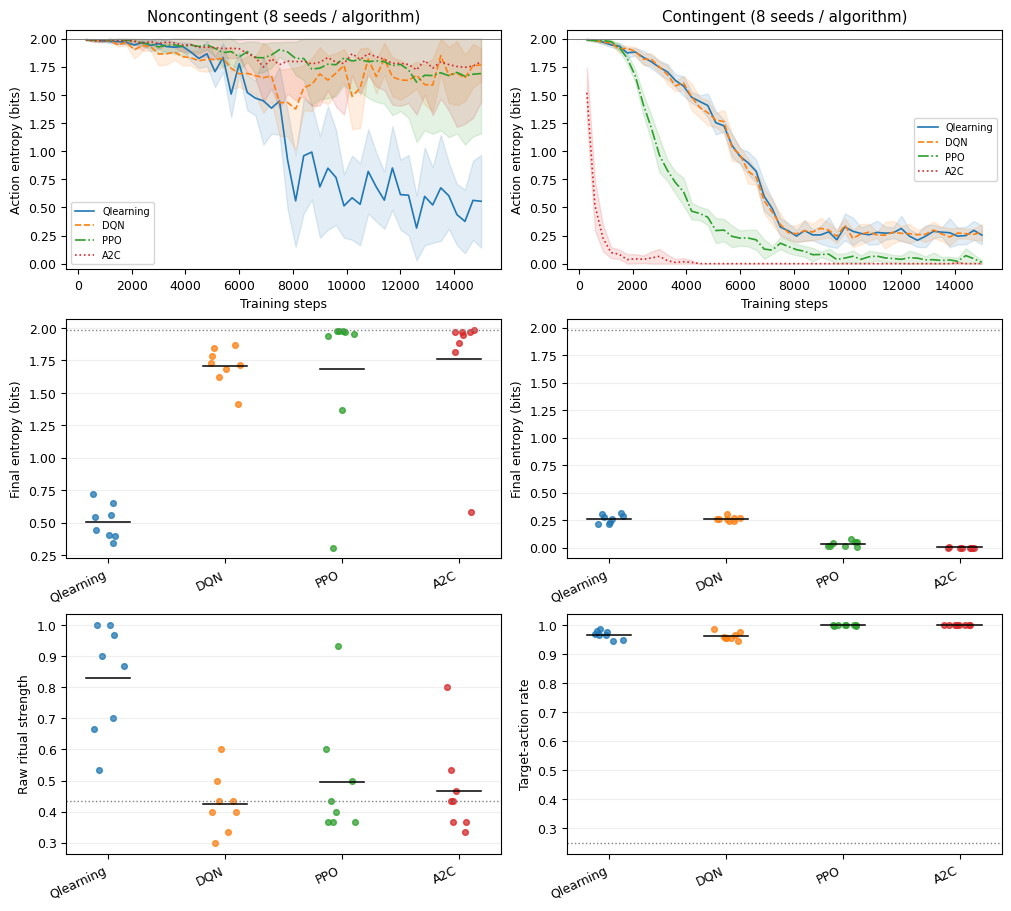

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


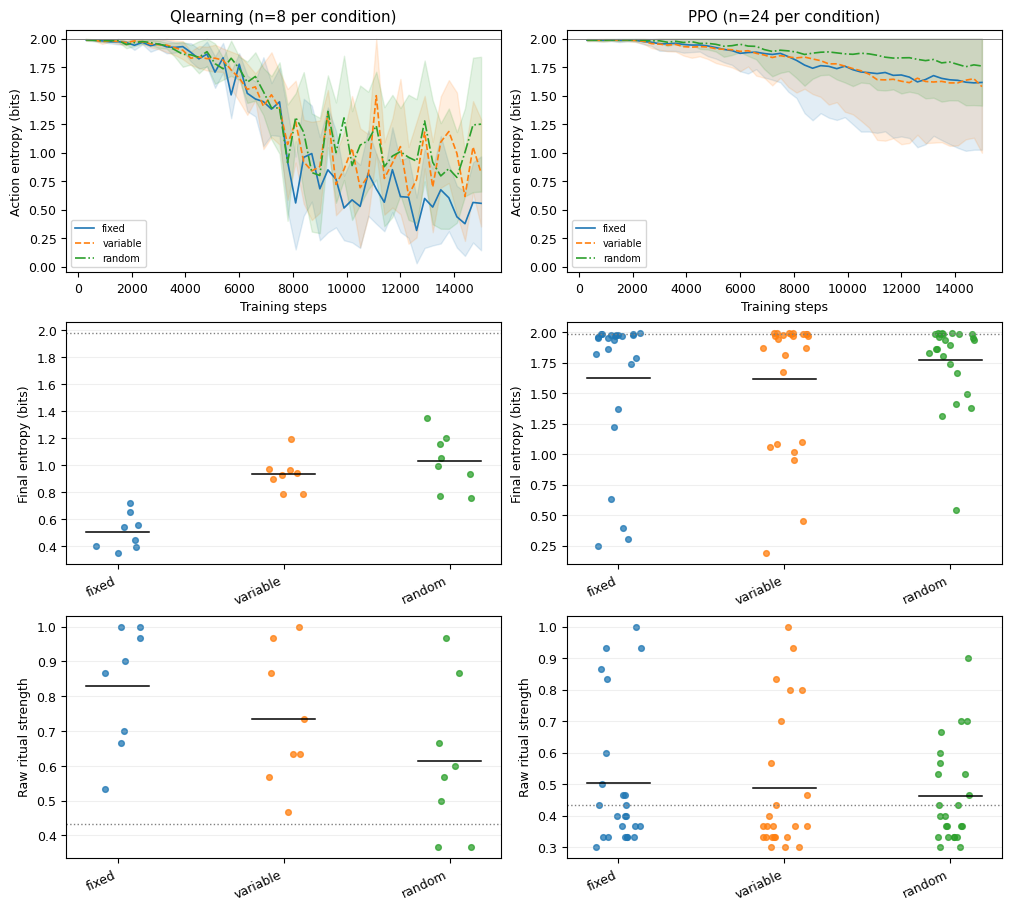

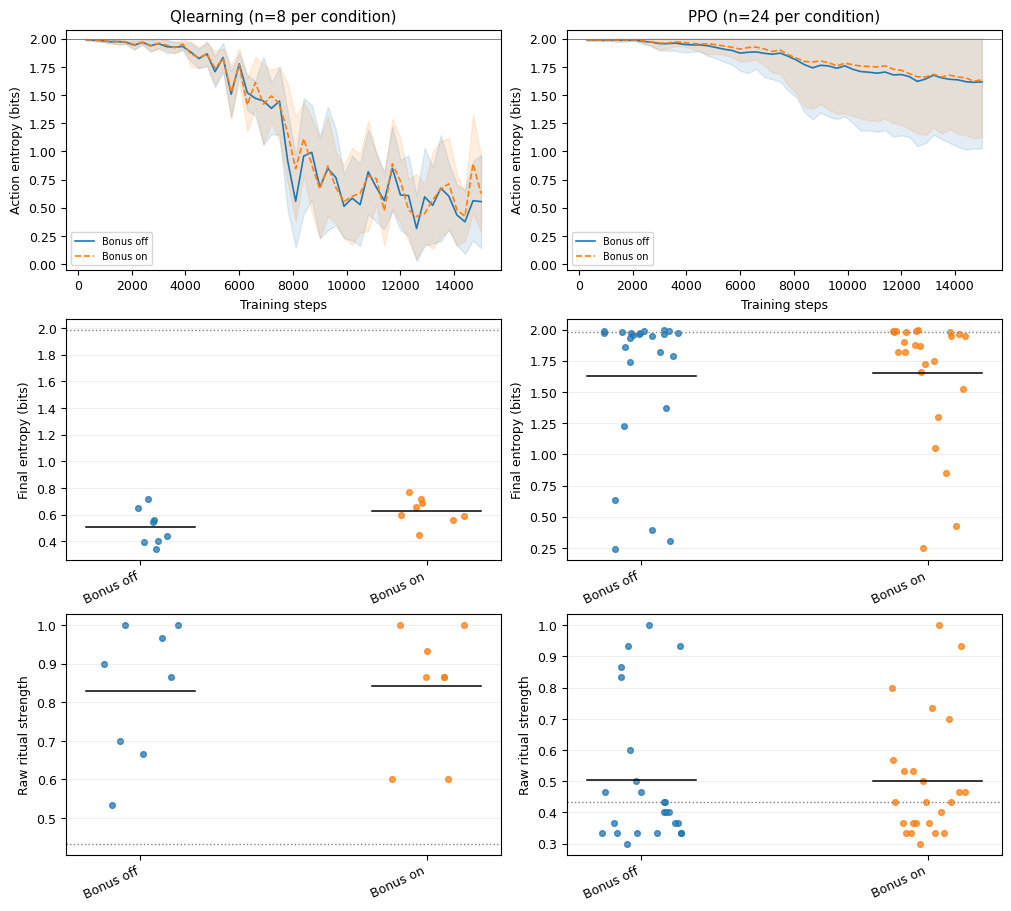

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [17]:
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 9,
                     'pdf.fonttype': 42, 'ps.fonttype': 42})

def entropy_matrix(runs):
    steps = np.array([x[0] for x in runs[0]['entropy_log']])
    curves = []
    for run in runs:
        current = np.array(run['entropy_log'])
        if not np.array_equal(current[:, 0], steps):
            raise ValueError('Cannot combine trajectories with different logging timesteps.')
        curves.append(current[:, 1])
    matrix = np.array(curves)
    return steps, matrix.mean(axis=0), matrix.std(axis=0, ddof=0)


def save_figure(fig, name):
    fig.savefig(FIG_DIR / f'{name}.pdf', bbox_inches='tight')
    fig.savefig(FIG_DIR / f'{name}.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def trajectory(ax, runs, label, color=None, style='-'):
    steps, mean, sd = entropy_matrix(runs)
    line, = ax.plot(steps, mean, label=label, color=color, linestyle=style, linewidth=1.2)
    ax.fill_between(steps, np.maximum(0, mean-sd), np.minimum(2, mean+sd),
                    color=line.get_color(), alpha=0.13)
    ax.set(xlabel='Training steps', ylabel='Action entropy (bits)', ylim=(-0.05, 2.08))
    ax.axhline(2, color='grey', linewidth=0.6)
    return line.get_color()


def strips(ax, groups, metric, threshold=None, ylabel=None, seed_key='strip'):
    rng = np.random.default_rng(stable_seed(123, seed_key, metric))
    for i, (label, runs, color) in enumerate(groups):
        vals = np.array([measure_run(r)[metric] for r in runs])
        vals = vals[np.isfinite(vals)]
        if len(vals):
            ax.scatter(i+rng.uniform(-0.14, 0.14, len(vals)), vals,
                       color=color, s=17, alpha=0.75)
            ax.plot([i-0.19, i+0.19], [vals.mean()]*2, color='black', linewidth=1.1)
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([g[0] for g in groups], rotation=25, ha='right')
    ax.set_ylabel(ylabel or metric.replace('_', ' '))
    if threshold is not None:
        ax.axhline(threshold, color='grey', linestyle=':', linewidth=1)
    ax.grid(axis='y', alpha=0.2)


fig, axes = plt.subplots(3, 2, figsize=(10, 9), constrained_layout=True)
for col, condition in enumerate(CONDITIONS):
    groups = []
    for i, algo in enumerate(ALGOS):
        runs = results_A[(algo, condition)]
        color = trajectory(axes[0, col], runs, algo, color=f'C{i}',
                            style=['-', '--', '-.', ':'][i])
        groups.append((algo, runs, color))
    axes[0, col].set_title(f'{condition.capitalize()} (8 seeds / algorithm)')
    axes[0, col].legend(fontsize=7)
    strips(axes[1, col], groups, 'final_entropy', NULL['entropy_p05'],
           'Final entropy (bits)', condition)
    strips(axes[2, col], groups,
           'ritual_strength' if condition == 'noncontingent' else 'target_rate',
           NULL['strength_p95'] if condition == 'noncontingent' else 0.25,
           'Raw ritual strength' if condition == 'noncontingent' else 'Target-action rate', condition)
save_figure(fig, 'Fig1_TierA_with_seed_strips')

for tier, results, levels, filename in [
    ('B', results_B, [(s, s) for s in SCHEDULES], 'Fig2_Schedules_with_seed_strips'),
    ('C', results_C, [(False, 'Bonus off'), (True, 'Bonus on')], 'Fig3_Bonus_with_seed_strips')]:
    fig, axes = plt.subplots(3, 2, figsize=(10, 9), constrained_layout=True)
    for col, algo in enumerate(TIER_B_ALGOS):
        groups = []
        for i, (key, label) in enumerate(levels):
            runs = results[(algo, key)]
            color = trajectory(axes[0, col], runs, label, f'C{i}', ['-', '--', '-.'][i])
            groups.append((label, runs, color))
        axes[0, col].set_title(f'{algo} (n={len(groups[0][1])} per condition)')
        axes[0, col].legend(fontsize=7)
        strips(axes[1, col], groups, 'final_entropy', NULL['entropy_p05'],
               'Final entropy (bits)', (tier, algo))
        strips(axes[2, col], groups, 'ritual_strength', NULL['strength_p95'],
               'Raw ritual strength', (tier, algo))
    save_figure(fig, filename)


## 15. Remaining figures and excess ritual-strength intervals

Figure 4 presents excess ritual strength across algorithms (with sample sizes labelled: n=8 for Q-learning and DQN, n=24 for PPO, n=16 for A2C), reward schedules, exploration bonus conditions, and interval lengths. Points indicate individual training seeds; error bars represent 95% bootstrap confidence intervals of the group mean excess.


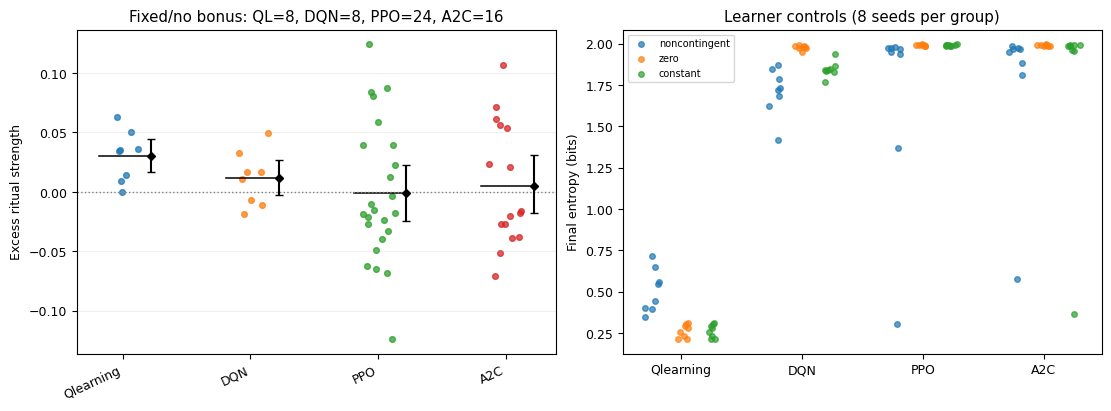

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


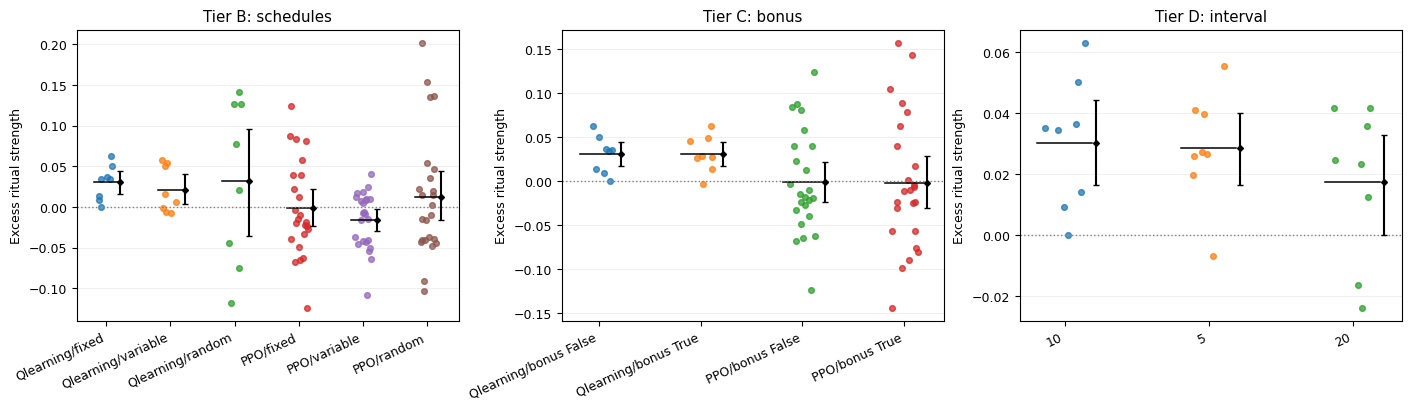

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


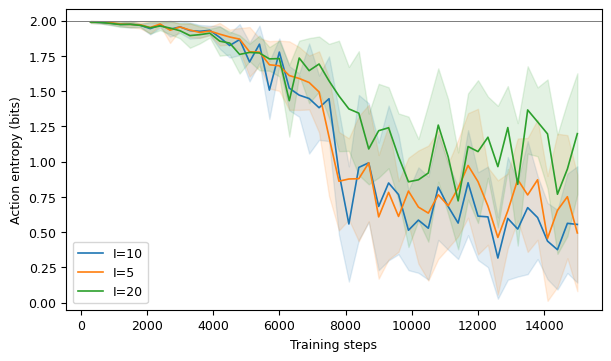

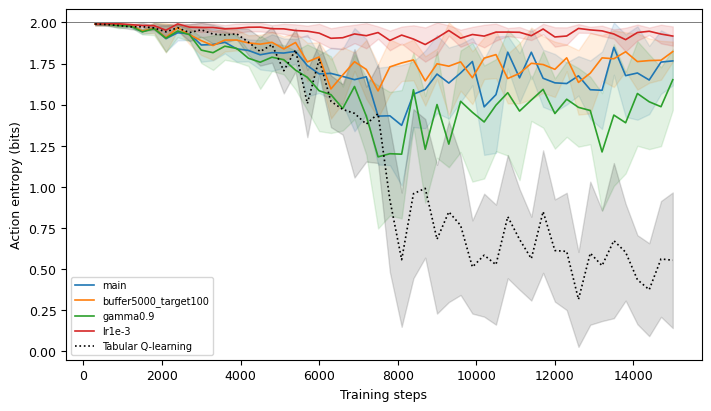

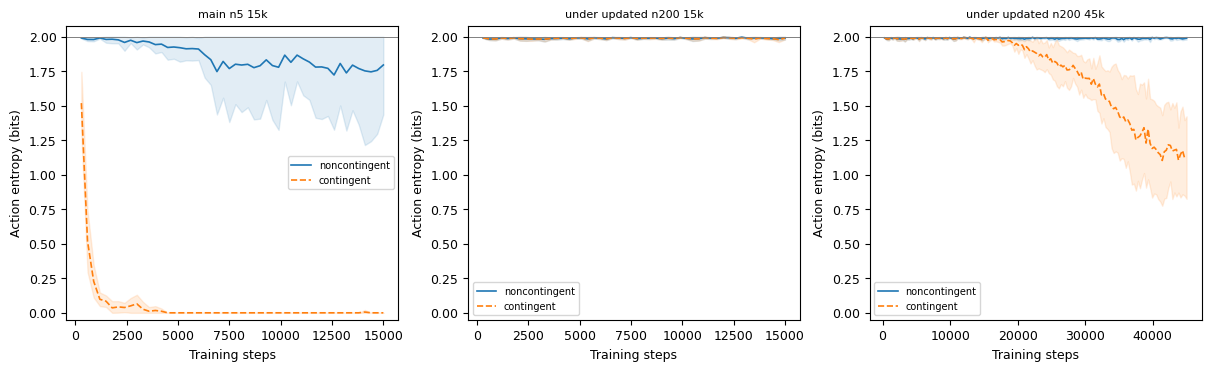

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
groups = [(a, NULL_RUNS[a], f'C{i}') for i, a in enumerate(ALGOS)]
strips(axes[0], groups, 'excess_ritual_strength', 0, 'Excess ritual strength', 'null_excess')
for i, (label, runs, _) in enumerate(groups):
    mean, lo, hi = bootstrap_mean_ci(summarize(runs)['excess_ritual_strength_vals'],
                                    key=('excess_figure', label))
    axes[0].errorbar(i+0.22, mean, yerr=[[max(0, mean-lo)], [max(0, hi-mean)]],
                     fmt='D', color='black', capsize=3, markersize=4)
axes[0].set_title('Fixed/no bonus: QL=8, DQN=8, PPO=24, A2C=16')
for i, algo in enumerate(ALGOS):
    for j, mode in enumerate(['noncontingent', 'zero', 'constant']):
        runs = results_A[(algo, mode)] if mode == 'noncontingent' else results_controls[(algo, mode)]
        vals = final_entropy_vals(runs)
        x = i + (j-1)*0.24
        jitter = np.random.default_rng(stable_seed(algo, mode)).uniform(-0.06, 0.06, len(vals))
        axes[1].scatter(x+jitter, vals, color=f'C{j}', s=16, alpha=0.7,
                         label=mode if i == 0 else None)
axes[1].set_xticks(range(4), ALGOS)
axes[1].set_ylabel('Final entropy (bits)')
axes[1].set_title('Learner controls (8 seeds per group)')
axes[1].legend(fontsize=7)
save_figure(fig, 'Fig_Excess_and_learner_controls')

panels = [('Tier B: schedules', [(f'{a}/{s}', r, f'C{i%10}')
           for i, ((a, s), r) in enumerate(results_B.items())]),
          ('Tier C: bonus', [(f'{a}/bonus {b}', r, f'C{i%10}')
           for i, ((a, b), r) in enumerate(results_C.items())]),
          ('Tier D: interval', [(str(k), r, f'C{i}') for i, (k, r) in enumerate(results_D.items())])]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, (title, groups) in zip(axes, panels):
    strips(ax, groups, 'excess_ritual_strength', 0, 'Excess ritual strength', title)
    for i, (label, runs, _) in enumerate(groups):
        mean, lo, hi = bootstrap_mean_ci(summarize(runs)['excess_ritual_strength_vals'], key=(title, label))
        ax.errorbar(i+0.22, mean, yerr=[[max(0, mean-lo)], [max(0, hi-mean)]],
                     fmt='D', color='black', capsize=2, markersize=3)
    ax.set_title(title)
save_figure(fig, 'Fig_Excess_B_C_D')

fig, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
for interval, runs in results_D.items():
    trajectory(ax, runs, f'I={interval}')
ax.legend()
save_figure(fig, 'Fig4_Interval')

if RUN_TIER_E:
    fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
    for name, runs in results_E.items():
        trajectory(ax, runs, name)
    trajectory(ax, results_A[('Qlearning', 'noncontingent')], 'Tabular Q-learning', 'black', ':')
    ax.legend(fontsize=7)
    save_figure(fig, 'Fig5_DQN_sensitivity')

fig, axes = plt.subplots(1, len(A2C_VARIANTS), figsize=(12, 3.6), constrained_layout=True)
for ax, name in zip(np.atleast_1d(axes), A2C_VARIANTS):
    for condition in CONDITIONS:
        trajectory(ax, results_F[(name, condition)], condition,
                    style='-' if condition == 'noncontingent' else '--')
    ax.set_title(name.replace('_', ' '), fontsize=8)
    ax.legend(fontsize=7)
save_figure(fig, 'Fig6_A2C_adequacy')


## 16. Statistical testing traceability and familywise corrections

All reported statistical tests are catalogued with uncorrected p-values, test statistics, sample sizes, and Holm–Bonferroni adjusted p-values within specified test families. Families include algorithm comparisons, schedule effects, exploration bonus tests, learner controls (8 entropy comparisons), uniform-null comparisons (entropy and raw strength), and excess-versus-zero tests. Traceability tables ensure full auditability of all statistical claims across all experimental tiers.


In [19]:
correction_df = apply_family_correction(TEST_LOG)
display_cols = ['design', 'family', 'm', 'holm_rank', 'multiplier', 'tier', 'context',
                'comparison', 'metric', 'p_raw', 'p_corrected',
                'significant_raw', 'significant_corrected']
trace_df = correction_df[display_cols].sort_values(['family', 'holm_rank']).reset_index(drop=True)
expected_m = {'final_entropy': 9, 'ritual_strength': 4, 'ritual_streak': 1,
               'interval_sensitivity_entropy': 1, 'interval_sensitivity_ritual': 1,
               'revision_learner_controls_entropy': 8,
               'revision_uniform_null_final_entropy': 4,
               'revision_uniform_null_ritual_strength': 4,
               'revision_excess_vs_zero': 4}
for family, expected in expected_m.items():
    got = int((correction_df.family == family).sum())
    assert got == expected, f'{family}: expected {expected}, got {got}; restart and run in order.'
correction_df.to_csv(TABLE_DIR / 'statistical_tests_corrected.csv', index=False)
trace_df.to_csv(TABLE_DIR / 'test_traceability_table.csv', index=False)
print('Revised total tests:', len(correction_df))
display(correction_df.groupby(['design', 'family']).size().rename('m').reset_index())
display(trace_df)
flipped = correction_df[correction_df.significant_raw & ~correction_df.significant_corrected]
print('Tests losing significance after correction:', len(flipped))
display(flipped[display_cols])

for name, selector in {
    'Table4_TierA_entropy_tests': (correction_df.tier == 'A') & (correction_df.family == 'final_entropy'),
    'Table5_Null_tests': correction_df.tier == 'Null',
    'Learner_control_tests': correction_df.tier == 'Controls',
    'Excess_vs_zero_tests': correction_df.tier == 'Shift',
}.items():
    correction_df[selector].to_csv(TABLE_DIR / f'{name}.csv', index=False)


Revised total tests: 68


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,design,family,m
0,original_design_reanalysis,final_entropy,9
1,original_design_reanalysis,ritual_streak,1
2,original_design_reanalysis,ritual_strength,4
3,post_hoc_robustness,interval_sensitivity_entropy,1
4,post_hoc_robustness,interval_sensitivity_ritual,1
5,reviewer_requested,revision_excess_vs_zero,4
6,reviewer_requested,revision_learner_controls_entropy,8
7,reviewer_requested,revision_uniform_null_final_entropy,4
8,reviewer_requested,revision_uniform_null_ritual_strength,4
9,supplementary,supp_a2c_entropy,2


,design,family,m,holm_rank,multiplier,tier,context,comparison,metric,p_raw,p_corrected,significant_raw,significant_corrected
0,original_design_reanalysis,final_entropy,9,1,9,A,Qlearning,noncontingent vs contingent,final_entropy,0.000155,0.001399,True,True
1,original_design_reanalysis,final_entropy,9,2,8,A,DQN,noncontingent vs contingent,final_entropy,0.000155,0.001399,True,True
2,original_design_reanalysis,final_entropy,9,3,7,B,Qlearning,fixed vs variable vs random,final_entropy,0.000377,0.002641,True,True
3,original_design_reanalysis,final_entropy,9,4,6,A,A2C,noncontingent vs contingent,final_entropy,0.000554,0.003321,True,True
4,original_design_reanalysis,final_entropy,9,5,5,A,noncontingent_n8_corrected_A2C,Qlearning vs DQN vs PPO vs A2C,final_entropy,0.000857,0.004283,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
63,supplementary,supp_tierD_schedule_ritual,6,2,5,D2,Qlearning_I=5,fixed vs random,ritual_strength,0.054261,0.271307,False,False
64,supplementary,supp_tierD_schedule_ritual,6,3,4,D2,Qlearning_I=5,fixed vs variable,ritual_strength,0.215672,0.862687,False,False
65,supplementary,supp_tierD_schedule_ritual,6,4,3,D2,Qlearning_I=20,fixed vs variable,ritual_strength,0.291841,0.875522,False,False
66,supplementary,supp_tierD_schedule_ritual,6,5,2,D2,Qlearning_I=10,fixed vs variable,ritual_strength,0.315921,0.875522,False,False


Tests losing significance after correction: 5


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,design,family,m,holm_rank,multiplier,tier,context,comparison,metric,p_raw,p_corrected,significant_raw,significant_corrected
9,reviewer_requested,revision_learner_controls_entropy,8,7,2,Controls,DQN,fixed_noncontingent vs constant,final_entropy,0.049883,0.099767,True,False
24,original_design_reanalysis,final_entropy,9,7,3,C,Qlearning,bonus OFF vs bonus ON,final_entropy,0.049883,0.149650,True,False
32,reviewer_requested,revision_uniform_null_ritual_strength,4,3,2,Null,DQN,DQN vs null(0.346983),ritual_strength,0.031250,0.062500,True,False
49,supplementary,supp_tierD_schedule_ritual,6,1,6,D2,Qlearning_I=10,fixed vs random,ritual_strength,0.045201,0.271208,True,False
58,supplementary,supp_dqn_ablation_entropy,6,5,2,E,vs_main_DQN,gamma0.9 vs main_DQN,final_entropy,0.037918,0.075835,True,False


## 17. Exports, reporting guidelines, and release archive

Every exported table includes exact numeric columns. The per-seed export (`per_seed_summary.csv`) records the run ID, random seed, experimental condition, training configuration, final entropy, raw ritual strength, shifted baseline mean, excess ritual strength, and analysis window definitions. Reused runs across tiers are indexed by their unique run ID. Complete action and reward traces for each run are stored in the checkpoint directory.

**Reporting and manuscript guidelines**
- Report both final action entropy and excess ritual strength; raw ritual strength should be interpreted as descriptive concentration rather than temporal reward alignment.
- When reporting learner controls, document the tie-breaking convention (`argmax` selecting the lowest index) and the theoretical random-exploration benchmark (~0.29 bits under epsilon-greedy).
- For A2C, report the primary 5-step rollout results alongside the 200-step under-updated control to illustrate the role of update frequency.
- Frame low entropy and action repetition as behavioural concentration under zero-information reward, rather than evidence of a subjective causal belief or reward-locking mechanism.
- Present bootstrap 95% confidence intervals across training seeds alongside hypothesis test results.

The cell below generates summary tables, per-seed CSVs, run metadata, and a bundled zip archive for archival release.


In [20]:

TIER_EXPORTS = {'A': (results_A, ['algorithm', 'condition']),
                'B': (results_B, ['algorithm', 'schedule']),
                'C': (results_C, ['algorithm', 'bonus']),
                'D': (results_D, ['interval']),
                'D2': (results_D2, ['schedule', 'interval']),
                'E': (results_E, ['dqn_variant']),
                'F': (results_F, ['a2c_variant', 'condition']),
                'Controls': (results_controls, ['algorithm', 'condition']),
                'ExpandedNull': (NULL_RUNS, ['algorithm'])}
rows = []
for tier, (groups, names) in TIER_EXPORTS.items():
    for key, runs in groups.items():
        key = key if isinstance(key, tuple) else (key,)
        for run in runs:
            row = dict(tier=tier, **dict(zip(names, key)), **measure_run(run))
            row['environment'] = json.dumps(run['config']['environment'], sort_keys=True)
            row['learner_kwargs'] = json.dumps(run['config']['learner_kwargs'], sort_keys=True)
            rows.append(row)
per_seed_df = pd.DataFrame(rows)
per_seed_df.to_csv(OUTPUT_ROOT / 'per_seed_summary.csv', index=False)
pd.DataFrame(RUN_REGISTRY.values()).to_csv(OUTPUT_ROOT / 'unique_training_runs.csv', index=False)
dqn_hparam_table.to_csv(TABLE_DIR / 'dqn_hyperparameter_overrides.csv', index=False)

null_excess_table = group_table(NULL_RUNS, ['algorithm'], 'Expanded_null_excess_CIs')
ppo_count = df_seed_counts.set_index('algorithm').loc['PPO']
n_ppo = int(ppo_count.n_raw_strength_above_uniform_p95)
note_lines = [
    '# Revised manuscript notes (generated after execution)',
    f'PPO: {n_ppo} of {int(ppo_count.n_seeds)} fixed/no-bonus seeds exceed the uniform-policy '
    f'raw-strength 95th percentile ({NULL["strength_p95"]:.6f}).',
    'This is a concentration criterion, not a reward-locking test.',
    f'PPO power conversion SD: {ppo_sd:.6f} bits; arithmetic mean of the three schedule SDs, ddof=0.',
    f'Revised number of logged tests: {len(correction_df)}.',
    '', 'Excess ritual strength (mean and seed-bootstrap 95% CI):']
for row in null_excess_table.to_dict('records'):
    note_lines.append(f'{row["algorithm"]}, n={row["n_seeds"]}: '
                      f'{row["excess_ritual_strength_mean"]:.6f} '
                      f'[{row["excess_ci95_lo"]:.6f}, {row["excess_ci95_hi"]:.6f}]')
note_lines += ['', 'Inspect the effect sizes and CI widths before describing an excess as near zero.',
               'A CI including zero alone does not establish equivalence or a causal mechanism.',
               '', 'Acknowledgments',
               'The authors gratefully acknowledge the support of the School of Computer Science and Engineering (SCOPE), VIT, Vellore.',
               '', 'Use of AI tools',
               'The authors used AI-assisted tools for language editing and improving the clarity and readability of the manuscript. The authors reviewed and approved the final content and take full responsibility for the published work.']
(OUTPUT_ROOT / 'manuscript_revision_notes.md').write_text('\n'.join(note_lines)+'\n', encoding='utf-8')
print('\n'.join(note_lines[:10]))

metadata = dict(versions=VERSIONS, trace_schema=TRACE_SCHEMA,
    analysis_version=ANALYSIS_VERSION, N_SEEDS=N_SEEDS,
    N_SEEDS_PPO_EXT=N_SEEDS_PPO_EXT, N_SEEDS_A2C_NULL=N_SEEDS_A2C_NULL,
    TOTAL_STEPS=TOTAL_STEPS, N_ACTIONS=N_ACTIONS, INTERVAL=INTERVAL,
    WINDOW=WINDOW, LOG_EVERY=LOG_EVERY, FINAL_ENTROPY_POINTS=FINAL_ENTROPY_POINTS,
    FINAL_ANALYSIS_STEPS=FINAL_ANALYSIS_STEPS, RITUAL_TAIL=RITUAL_TAIL,
    N_SHIFTS=N_SHIFTS, SHIFT_SEED=SHIFT_SEED, N_BOOT=N_BOOT, BOOT_SEED=BOOT_SEED,
    null_baseline=NULL, power_summary=power_summary, expected_family_sizes=expected_m,
    test_count=len(correction_df), unique_training_runs=len(RUN_REGISTRY),
    sd_convention='ddof=0 descriptive SD; ddof=1 pooled SD for Cohens d',
    main_A2C_n_steps=5, old_A2C_control_n_steps=200,
    flags=dict(D2=RUN_TIER_D_SCHEDULES, E=RUN_TIER_E, A2C_45k=RUN_A2C_45K_CONTROL))
(OUTPUT_ROOT / 'run_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
(OUTPUT_ROOT / 'README.txt').write_text(
    'v4 revised RL study. per_seed_summary.csv has reused rows across tiers. '
    'Use unique run_id/seed for independent replicates. Full aligned actions and '
    'extrinsic rewards are in run_cache/*.json.gz. Times are 1-based reward timestamps. '
    'Tables/figures are generated from these traces. No-reward ritual measures are undefined. '
    'See notebook for inference families, final-window definition and limitations.\n', encoding='utf-8')

archive_base = OUTPUT_ROOT.parent / 'superstitious_rl_v4_release'
archive = shutil.make_archive(str(archive_base), 'zip', root_dir=OUTPUT_ROOT.parent,
                               base_dir=OUTPUT_ROOT.name)
print('Release archive:', archive)
print('Completed unique training runs:', len(RUN_REGISTRY))
print('All outputs:', OUTPUT_ROOT.resolve())


# Revised manuscript notes (generated after execution)
PPO: 9 of 24 fixed/no-bonus seeds exceed the uniform-policy raw-strength 95th percentile (0.433333).
This is a concentration criterion, not a reward-locking test.
PPO power conversion SD: 0.484455 bits; arithmetic mean of the three schedule SDs, ddof=0.
Revised number of logged tests: 68.

Excess ritual strength (mean and seed-bootstrap 95% CI):
Qlearning, n=8: 0.030267 [0.016783, 0.044038]
DQN, n=8: 0.011271 [-0.003134, 0.026763]
PPO, n=24: -0.001233 [-0.023520, 0.022010]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Release archive: /content/superstitious_rl_v4_release.zip
Completed unique training runs: 352
All outputs: /content/results_v4
